# Spatial Filter-Based Noise Reduction and Its Impact on Edge Detection

---
**Hypothesis:** Running edge detection on a *denoised* image gives edge maps much closer to the
clean image's edges than running it directly on the *noisy* image.

---
**Experimental design**
1. Clean images are the ground truth.
2. Three noise types are added: `Salt & Pepper`, `Gaussian`, `Mixed (Gaussian + S&P)`.
3. Six denoisers are applied to **every** noise type: `Mean`, `Median`, `Gaussian`, `Bilateral`,
   `Non-Local Means`, and a `Median→Bilateral cascade`. No filter is hand-picked in advance.
4. Three edge detectors (Sobel, Canny, LoG) run on Original / Noisy / every Denoised version
   with **identical frozen parameters** (calibrated on the clean image only).
5. Image quality: PSNR + SSIM. Edge quality: Precision / Recall / F1 against the clean image's edges.
6. Conclusions are computed from the numbers, nothing is hard-coded.
7. Extra: noise-level sweep, parameter sensitivity, from-scratch filter verification,
   and a cell for your own real-world noisy images.

In [1]:
# imports
import os, time, warnings
import numpy as np
import cv2
import pandas as pd
import matplotlib.pyplot as plt
from numpy.lib.stride_tricks import sliding_window_view
from skimage import data
from skimage.metrics import structural_similarity

warnings.filterwarnings('ignore')
plt.rcParams['figure.dpi'] = 100

# configs
SEED = 42  # reproducibility
IMG_SIZE = 512   # every image is centre-cropped to a square and resized to this to ensure consistent processing and fair comparison

# noise settings
NOISE_CONFIG = {
    'salt_pepper': dict(kind='salt_pepper', density=0.05,             label='Salt & Pepper (5%)'),
    'gaussian':    dict(kind='gaussian',    sigma=25,                  label='Gaussian (sigma=25)'),
    'mixed':       dict(kind='mixed',       sigma=15, density=0.02,    label='Mixed (sigma=15 + 2% S&P)'),
}

# edge detection settings
EDGE_PERCENTILE = 90           # top 10% strongest gradients of the CLEAN image count as edges (Sobel/Canny)
CANNY_SIGMA = 1.4              # Gaussian smoothing before Canny (cv2.Canny does NOT smooth by itself)
LOG_SIGMA = 1.5                # LoG scale
LOG_STRENGTH_PERCENTILE = 75   # keep zero-crossings stronger than this percentile of the clean image's crossings
EDGE_TOL = 1                   # a predicted edge pixel is "correct" if a true edge is within this many pixels

# ---------- experiment extras ----------
SWEEP_IMAGES = ['Camera Man', 'Coins']   # images used for the noise-level sweep
SHOW_ALL_EDGE_GRIDS = False              # True = draw the big edge grid for every image x noise (12 figures)

In [2]:
# output folder
OUT_DIR = '/kaggle/working/outputs' if os.path.exists('/kaggle/working') else './outputs'
os.makedirs(OUT_DIR, exist_ok=True)
SAVED = []

def save_fig(fig, name):
    path = os.path.join(OUT_DIR, name)
    fig.savefig(path, dpi=130, bbox_inches='tight')
    SAVED.append(path)

print('Outputs will be saved to:', os.path.abspath(OUT_DIR))

Outputs will be saved to: /kaggle/working/outputs


## 1. Reference (clean) images
Built-in images (no upload needed). Each one is centre-cropped to a square and resized to 512x512
so all images are treated identically.

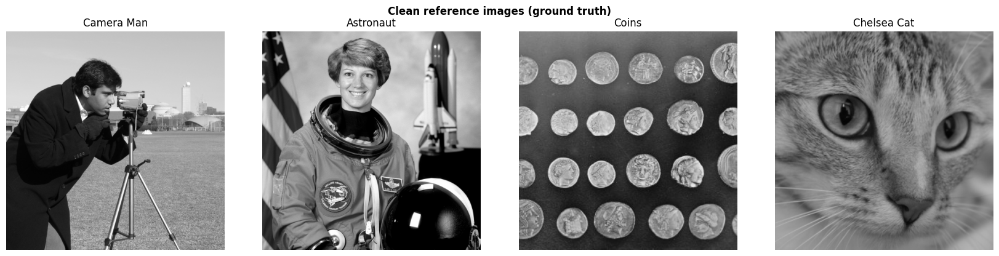

{'Camera Man': (512, 512), 'Astronaut': (512, 512), 'Coins': (512, 512), 'Chelsea Cat': (512, 512)}


In [3]:
def to_gray(img):
    if img.ndim == 3:
        return cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
    return img

def center_square_resize(img, size):
    h, w = img.shape[:2]
    s = min(h, w)
    y0, x0 = (h - s) // 2, (w - s) // 2
    img = img[y0:y0 + s, x0:x0 + s]
    return cv2.resize(img, (size, size), interpolation=cv2.INTER_AREA)

def load_reference_images():
    loaders = {'Camera Man': data.camera, 'Astronaut': data.astronaut,
               'Coins': data.coins, 'Chelsea Cat': data.chelsea}
    out = {}
    for name, fn in loaders.items():
        try:
            img = fn()
            out[name] = center_square_resize(to_gray(img).astype(np.uint8), IMG_SIZE)
        except Exception as e:
            print(f'  ! could not load {name}: {e}')
    return out

IMAGES = load_reference_images()
IMG_INDEX = {n: i for i, n in enumerate(IMAGES)}
NOISE_INDEX = {k: j for j, k in enumerate(NOISE_CONFIG)}

fig, axes = plt.subplots(1, len(IMAGES), figsize=(4.2 * len(IMAGES), 4.2))
axes = np.atleast_1d(axes)
for ax, (n, im) in zip(axes, IMAGES.items()):
    ax.imshow(im, cmap='gray', vmin=0, vmax=255)
    ax.set_title(n)
    ax.axis('off')
fig.suptitle('Clean reference images (ground truth)', fontweight='bold')
plt.tight_layout()
save_fig(fig, '01_reference_images.png')
plt.show()
print({k: v.shape for k, v in IMAGES.items()})

## 2. Noise models
* **Salt & Pepper** – a random fraction of pixels is forced to 0 or 255 (sensor faults, transmission errors).
* **Gaussian** – every pixel gets a zero-mean random offset (thermal / low-light sensor noise).
* **Mixed** – Gaussian first, then a little S&P. This is closer to a real camera, which has several noise sources at once.
---
Every (image, noise) pair has its own fixed random seed, so rerunning the notebook gives the **same numbers**.

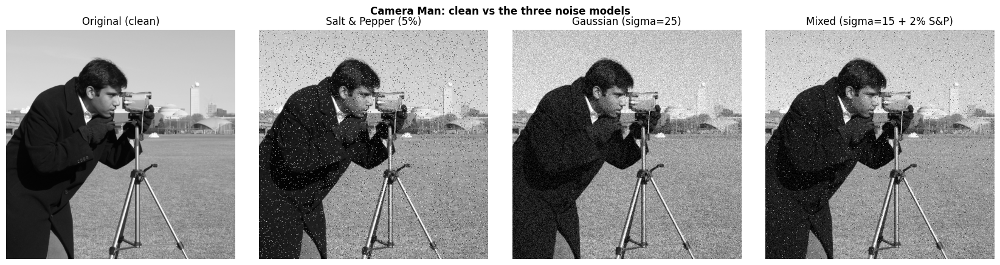

In [4]:
# Noise functions + deterministic noisy images
def add_salt_pepper(img, density, rng):
    noisy = img.copy()
    r = rng.random(img.shape)
    noisy[r < density / 2] = 0                              # pepper
    noisy[(r >= density / 2) & (r < density)] = 255         # salt
    return noisy

def add_gaussian(img, sigma, rng):
    noisy = img.astype(np.float64) + rng.normal(0.0, sigma, img.shape)
    return np.clip(np.rint(noisy), 0, 255).astype(np.uint8)  # rint (not truncate) -> no systematic bias

def make_noisy(img, cfg, rng):
    kind = cfg['kind']
    if kind == 'salt_pepper':
        return add_salt_pepper(img, cfg['density'], rng)
    if kind == 'gaussian':
        return add_gaussian(img, cfg['sigma'], rng)
    if kind == 'mixed':
        return add_salt_pepper(add_gaussian(img, cfg['sigma'], rng), cfg['density'], rng)
    raise ValueError(kind)

NOISY = {}
def get_noisy(img_name, noise_key):
    key = (img_name, noise_key)
    if key not in NOISY:
        rng = np.random.default_rng([SEED, IMG_INDEX[img_name], NOISE_INDEX[noise_key]])
        NOISY[key] = make_noisy(IMAGES[img_name], NOISE_CONFIG[noise_key], rng)
    return NOISY[key]

first = next(iter(IMAGES))
fig, axes = plt.subplots(1, 1 + len(NOISE_CONFIG), figsize=(4.2 * (1 + len(NOISE_CONFIG)), 4.4))
axes[0].imshow(IMAGES[first], cmap='gray', vmin=0, vmax=255)
axes[0].set_title('Original (clean)')
for ax, (k, cfg) in zip(axes[1:], NOISE_CONFIG.items()):
    ax.imshow(get_noisy(first, k), cmap='gray', vmin=0, vmax=255)
    ax.set_title(cfg['label'])
for ax in axes: ax.axis('off')
fig.suptitle(f'{first}: clean vs the three noise models', fontweight='bold')
plt.tight_layout()
save_fig(fig, '02_noise_models.png')
plt.show()

## 3. Metrics
**Image quality** (denoised vs clean): PSNR (pixel error) and SSIM (structural similarity — it punishes blur).

---
**Edge quality** (edge map of a version vs edge map of the clean image, 1-pixel tolerance):
* **Precision** – of the edges we detected, how many are real? *(low = false edges caused by noise)*
* **Recall** – of the real edges, how many did we find? *(low = real edges blurred away or missed)*
* **F1** – harmonic mean of the two. **This is the main edge metric.**

In [5]:
# Metric functions
def psnr(a, b):
    mse = np.mean((a.astype(np.float64) - b.astype(np.float64)) ** 2)
    return float('inf') if mse == 0 else 10 * np.log10(255.0 ** 2 / mse)

def ssim(a, b):
    return float(structural_similarity(a, b, data_range=255))

def edge_scores(pred, gt, tol=EDGE_TOL):
    """Precision / Recall / F1 of binary edge map `pred` against `gt`, with `tol`-pixel tolerance."""
    p, g = pred > 0, gt > 0
    k = np.ones((2 * tol + 1, 2 * tol + 1), np.uint8)
    p_near = cv2.dilate(p.astype(np.uint8), k) > 0     # pixels within tol of a predicted edge
    g_near = cv2.dilate(g.astype(np.uint8), k) > 0     # pixels within tol of a true edge
    n_p, n_g = int(p.sum()), int(g.sum())
    prec = (p & g_near).sum() / max(n_p, 1)
    rec = (g & p_near).sum() / max(n_g, 1)
    f1 = 0.0 if (prec + rec) == 0 else 2 * prec * rec / (prec + rec)
    return dict(Precision=float(prec), Recall=float(rec), F1=float(f1),
                FalseEdgePx=int(n_p - (p & g_near).sum()), EdgeDensity=float(p.mean()))

# sanity checks
a = IMAGES['Camera Man']
print('PSNR(clean, clean)           =', psnr(a, a), '(inf expected)')
print('SSIM(clean, clean)           =', round(ssim(a, a), 4), '(1.0 expected)')
print('PSNR(clean, noisy S&P)       =', round(psnr(a, get_noisy(first, 'salt_pepper')), 2), 'dB')
print('PSNR(clean, noisy Gaussian)  =', round(psnr(a, get_noisy(first, 'gaussian')), 2), 'dB')

PSNR(clean, clean)           = inf (inf expected)
SSIM(clean, clean)           = 1.0 (1.0 expected)
PSNR(clean, noisy S&P)       = 17.85 dB
PSNR(clean, noisy Gaussian)  = 20.62 dB


## 4. Denoising filters (the same six are tested on every noise type)
| Filter | Idea | Expected strength |
|---|---|---|
| Mean 5x5 | plain average | blurs edges; weak on S&P |
| Median 5x5 | median of neighbourhood | outliers ignored, strong on S&P |
| Gaussian 5x5 | weighted average | good on Gaussian noise, blurs edges |
| Bilateral | weights by distance **and** intensity similarity | preserves edges, but treats S&P pixels as edges |
| Non-Local Means | averages similar patches from the whole neighbourhood (h fixed = 15) | strong on moderate Gaussian noise; h must scale with sigma |
| Median3 + Bilateral | cascade: remove impulses first, then smooth | designed for mixed noise |

---
The "expected" column is what theory suggests. The experiment decides what is actually true.

Parameters are fixed (not tuned per noise type) for a fair comparison. The sensitivity section later checks how much this matters.

In [6]:
# Filter registry
FILTERS = {
    'Mean 5x5':          lambda im: cv2.blur(im, (5, 5)),
    'Median 5x5':        lambda im: cv2.medianBlur(im, 5),
    'Gaussian 5x5':      lambda im: cv2.GaussianBlur(im, (5, 5), 1.5),
    'Bilateral':         lambda im: cv2.bilateralFilter(im, 9, 75, 75),
    'NL-Means':          lambda im: cv2.fastNlMeansDenoising(im, None, h=15, templateWindowSize=7, searchWindowSize=21),
    'Median3+Bilateral': lambda im: cv2.bilateralFilter(cv2.medianBlur(im, 3), 9, 50, 50),
}
BASELINE = 'None (noisy)'            # "no denoising" row used as the comparison baseline
ALL_VARIANTS = [BASELINE] + list(FILTERS)
print('Filters:', list(FILTERS))

Filters: ['Mean 5x5', 'Median 5x5', 'Gaussian 5x5', 'Bilateral', 'NL-Means', 'Median3+Bilateral']


## 5. Edge detectors
| Detector | Smoothing inside? | Note |
|---|---|---|
| Sobel | **none** | gradient magnitude > threshold, so it is expected to be the most noise-sensitive |
| Canny | Gaussian (we add it explicitly) | `cv2.Canny` itself does not smooth, so we blur first as in the textbook algorithm |
| LoG | Gaussian + Laplacian | edges = zero-crossings of the response with sufficient strength |

---
**Fair-comparison rule:** each threshold is calibrated **once, on the clean image only**, and then the *same*
values are used for the noisy and all denoised versions. If thresholds were re-tuned per version, a noisy
image could be made to look fine by simply raising the threshold.

Calibrated thresholds (from clean images only):
             sobel_thr  canny_high  canny_low  log_thr
Camera Man      124.40       63.64      25.46     1.83
Astronaut       176.12      125.87      50.35     3.26
Coins           141.82       90.08      36.03     1.99
Chelsea Cat      88.57       55.79      22.31     1.88

Edge density of CLEAN images (fraction of pixels marked as edge):
             Sobel  Canny    LoG
Camera Man     0.1  0.043  0.089
Astronaut      0.1  0.054  0.061
Coins          0.1  0.052  0.083
Chelsea Cat    0.1  0.081  0.073


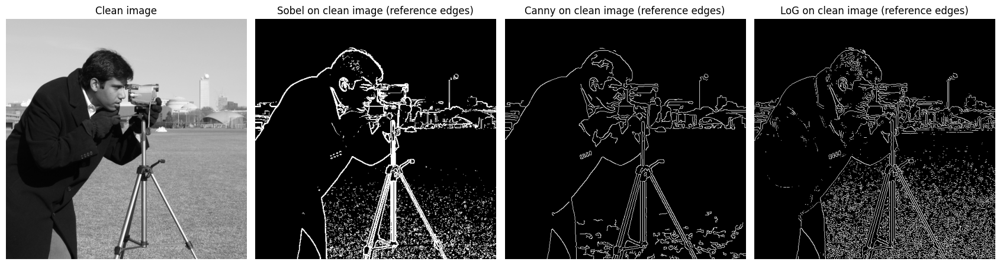

In [7]:
# Edge detectors + calibration on the clean image
DETECTORS = ['Sobel', 'Canny', 'LoG']

def sobel_magnitude(img):
    gx = cv2.Sobel(img, cv2.CV_64F, 1, 0, ksize=3)
    gy = cv2.Sobel(img, cv2.CV_64F, 0, 1, ksize=3)
    return np.hypot(gx, gy)

def log_response(img):
    g = cv2.GaussianBlur(img.astype(np.float32), (0, 0), LOG_SIGMA)
    return cv2.Laplacian(g, cv2.CV_32F, ksize=1)

def _zero_cross_parts(resp):
    a, b = resp[:, :-1], resp[:, 1:]
    c, d = resp[:-1, :], resp[1:, :]
    return (a * b < 0), np.abs(a - b), (c * d < 0), np.abs(c - d)

def crossing_strengths(resp):
    h, hs, v, vs = _zero_cross_parts(resp)
    return np.concatenate([hs[h], vs[v]])

def log_edges(img, thr):
    resp = log_response(img)
    h, hs, v, vs = _zero_cross_parts(resp)
    e = np.zeros(resp.shape, bool)
    e[:, :-1] |= h & (hs > thr)
    e[:-1, :] |= v & (vs > thr)
    return (e * 255).astype(np.uint8)

def calibrate_detectors(clean):
    mag = sobel_magnitude(clean)
    smooth = cv2.GaussianBlur(clean, (0, 0), CANNY_SIGMA)
    mag_s = sobel_magnitude(smooth)
    c_high = float(np.percentile(mag_s, EDGE_PERCENTILE))
    return dict(sobel_thr=float(np.percentile(mag, EDGE_PERCENTILE)),
                canny_high=c_high, canny_low=0.4 * c_high,
                log_thr=float(np.percentile(crossing_strengths(log_response(clean)), LOG_STRENGTH_PERCENTILE)))

def detect(name, img, p):
    """Return a binary edge map (0/255, uint8) using the frozen parameters in `p`."""
    if name == 'Sobel':
        return ((sobel_magnitude(img) > p['sobel_thr']) * 255).astype(np.uint8)
    if name == 'Canny':
        sm = cv2.GaussianBlur(img, (0, 0), CANNY_SIGMA)
        return cv2.Canny(sm, p['canny_low'], p['canny_high'], L2gradient=True)
    if name == 'LoG':
        return log_edges(img, p['log_thr'])
    raise ValueError(name)

DET_PARAMS = {n: calibrate_detectors(im) for n, im in IMAGES.items()}
ORIG_EDGES = {n: {d: detect(d, im, DET_PARAMS[n]) for d in DETECTORS} for n, im in IMAGES.items()}

print('Calibrated thresholds (from clean images only):')
print(pd.DataFrame(DET_PARAMS).T.round(2).to_string())
print('\nEdge density of CLEAN images (fraction of pixels marked as edge):')
print(pd.DataFrame({n: {d: ORIG_EDGES[n][d].mean() / 255 for d in DETECTORS} for n in IMAGES}).T.round(3).to_string())

fig, axes = plt.subplots(1, 4, figsize=(17, 4.4))
axes[0].imshow(IMAGES[first], cmap='gray')
axes[0].set_title('Clean image')
for ax, d in zip(axes[1:], DETECTORS):
    ax.imshow(ORIG_EDGES[first][d], cmap='gray')
    ax.set_title(f'{d} on clean image (reference edges)')
for ax in axes: ax.axis('off')
plt.tight_layout()
save_fig(fig, '04_reference_edges.png')
plt.show()

## 6. Main experiment
For every `image x noise` type we run: no-denoising baseline + 6 filters, and for every one of those versions we measure PSNR, SSIM, and Precision/Recall/F1 for all 3 edge detectors. All raw results are saved as CSV.

In [8]:
# Run the full experiment
def evaluate_variants(orig, noisy, params, orig_edges):
    """Apply every filter to `noisy`; measure image quality and edge quality for every version."""
    variants, times = {BASELINE: noisy}, {BASELINE: 0.0}
    for fname, fn in FILTERS.items():
        t0 = time.perf_counter()
        variants[fname] = fn(noisy)
        times[fname] = (time.perf_counter() - t0) * 1000
    q_rows, e_rows, emaps = [], [], {}
    for vname, vimg in variants.items():
        q_rows.append(dict(Filter=vname, PSNR=psnr(orig, vimg), SSIM=ssim(orig, vimg), Time_ms=times[vname]))
        for d in DETECTORS:
            e = detect(d, vimg, params)
            emaps[(vname, d)] = e
            e_rows.append(dict(Filter=vname, Detector=d, **edge_scores(e, orig_edges[d])))
    return variants, q_rows, e_rows, emaps

STORE, EDGE_MAPS = {}, {}
q_all, e_all = [], []
t_start = time.time()
for iname, orig in IMAGES.items():
    for nkey in NOISE_CONFIG:
        noisy = get_noisy(iname, nkey)
        variants, q, e, em = evaluate_variants(orig, noisy, DET_PARAMS[iname], ORIG_EDGES[iname])
        STORE[(iname, nkey)] = variants
        q_all += [dict(Image=iname, Noise=nkey, **r) for r in q]
        e_all += [dict(Image=iname, Noise=nkey, **r) for r in e]
        EDGE_MAPS.update({(iname, nkey, v, d): m for (v, d), m in em.items()})
    print(f'  done: {iname}')

quality_df = pd.DataFrame(q_all)
edge_df = pd.DataFrame(e_all)
quality_df.to_csv(os.path.join(OUT_DIR, 'results_quality.csv'), index=False)
edge_df.to_csv(os.path.join(OUT_DIR, 'results_edges.csv'), index=False)
print(f'\nExperiment finished in {time.time() - t_start:.1f}s | '
      f'{len(quality_df)} quality rows, {len(edge_df)} edge rows saved to {OUT_DIR}')

  done: Camera Man
  done: Astronaut
  done: Coins
  done: Chelsea Cat

Experiment finished in 8.5s | 84 quality rows, 252 edge rows saved to /kaggle/working/outputs


In [9]:
cam_quality = quality_df[quality_df['Image'] == 'Camera Man']
cam_edges = edge_df[edge_df['Image'] == 'Camera Man']

# 1. Best Filter by PSNR (Peak Signal-to-Noise Ratio) per noise type
best_psnr = cam_quality.loc[cam_quality.groupby('Noise')['PSNR'].idxmax()]
print("--- Best PSNR by Noise Type ---")
print(best_psnr[['Noise', 'Filter', 'PSNR', 'SSIM']])

# 2. Best Filter by SSIM (Structural Similarity) per noise type
best_ssim = cam_quality.loc[cam_quality.groupby('Noise')['SSIM'].idxmax()]
print("\n--- Best SSIM by Noise Type ---")
print(best_ssim[['Noise', 'Filter', 'PSNR', 'SSIM']])

# 3. Best Filter by Edge F1 Score per noise type and detector
best_f1 = cam_edges.loc[cam_edges.groupby(['Noise', 'Detector'])['F1'].idxmax()]
print("\n--- Best Edge F1 Score by Noise Type & Detector ---")
print(best_f1[['Noise', 'Detector', 'Filter', 'F1', 'Precision', 'Recall']])

--- Best PSNR by Noise Type ---
          Noise             Filter       PSNR      SSIM
11     gaussian          Bilateral  27.589174  0.714989
20        mixed  Median3+Bilateral  27.720156  0.744619
6   salt_pepper  Median3+Bilateral  28.112548  0.767077

--- Best SSIM by Noise Type ---
          Noise             Filter       PSNR      SSIM
11     gaussian          Bilateral  27.589174  0.714989
20        mixed  Median3+Bilateral  27.720156  0.744619
2   salt_pepper         Median 5x5  27.868749  0.796207

--- Best Edge F1 Score by Noise Type & Detector ---
          Noise Detector        Filter        F1  Precision    Recall
31     gaussian    Canny  Gaussian 5x5  0.798462   0.938467  0.694808
38     gaussian      LoG      NL-Means  0.818507   0.752089  0.897793
36     gaussian    Sobel      NL-Means  0.855177   0.763995  0.971074
52        mixed    Canny  Gaussian 5x5  0.789349   0.911666  0.695971
59        mixed      LoG      NL-Means  0.642986   0.549910  0.773988
51        mixe

## 7. Visual results
**7a.** What each denoiser does to each noise type (full image, then a zoomed crop where differences are easier to see).

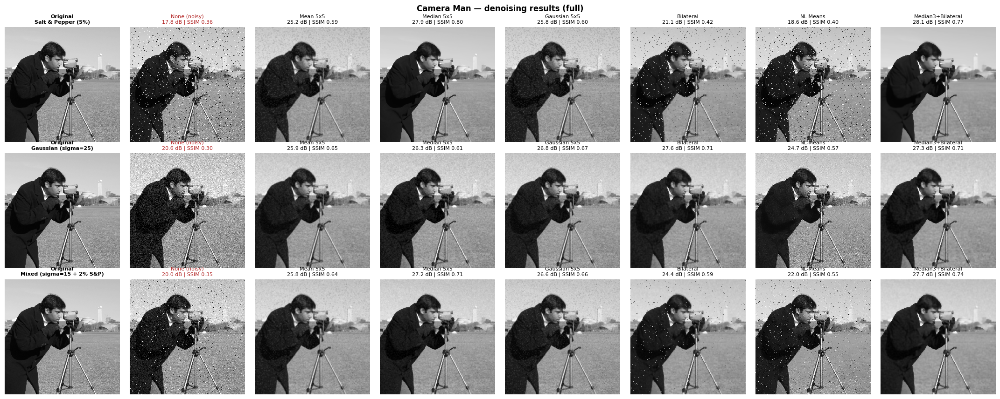

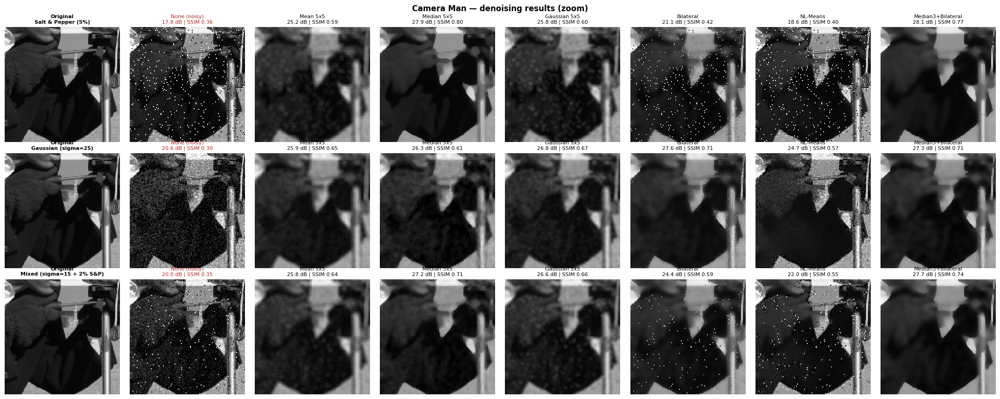

In [10]:
# Denoising result grids
def qlookup(img, noise, variant):
    r = quality_df[(quality_df.Image == img) & (quality_df.Noise == noise) & (quality_df.Filter == variant)].iloc[0]
    return r.PSNR, r.SSIM

def denoise_grid(img_name, crop=None, tag='full'):
    cols = ['Original'] + ALL_VARIANTS
    fig, axes = plt.subplots(len(NOISE_CONFIG), len(cols), figsize=(2.7 * len(cols), 2.9 * len(NOISE_CONFIG)))
    for r, nkey in enumerate(NOISE_CONFIG):
        for c, v in enumerate(cols):
            img = IMAGES[img_name] if v == 'Original' else STORE[(img_name, nkey)][v]
            if crop: y, x, s = crop; img = img[y:y + s, x:x + s]
            ax = axes[r][c]
            ax.imshow(img, cmap='gray', vmin=0, vmax=255, interpolation='nearest')
            ax.axis('off')
            if v == 'Original':
                ax.set_title(f'Original\n{NOISE_CONFIG[nkey]["label"]}', fontsize=8, fontweight='bold')
            else:
                p, s_ = qlookup(img_name, nkey, v)
                ax.set_title(f'{v}\n{p:.1f} dB | SSIM {s_:.2f}', fontsize=8, color='firebrick' if v == BASELINE else 'black')
    fig.suptitle(f'{img_name} — denoising results ({tag})', fontweight='bold')
    plt.tight_layout()
    save_fig(fig, f'05_denoise_grid_{img_name.replace(" ", "")}_{tag}.png')
    plt.show()

denoise_grid(first)
denoise_grid(first, crop=(180, 180, 128), tag='zoom')

**7b.** Edge detection on Original / Noisy / every Denoised version. Edge maps are white on black.
The title of each edge map shows its **F1 against the clean image's edge map** (higher = closer to the original).

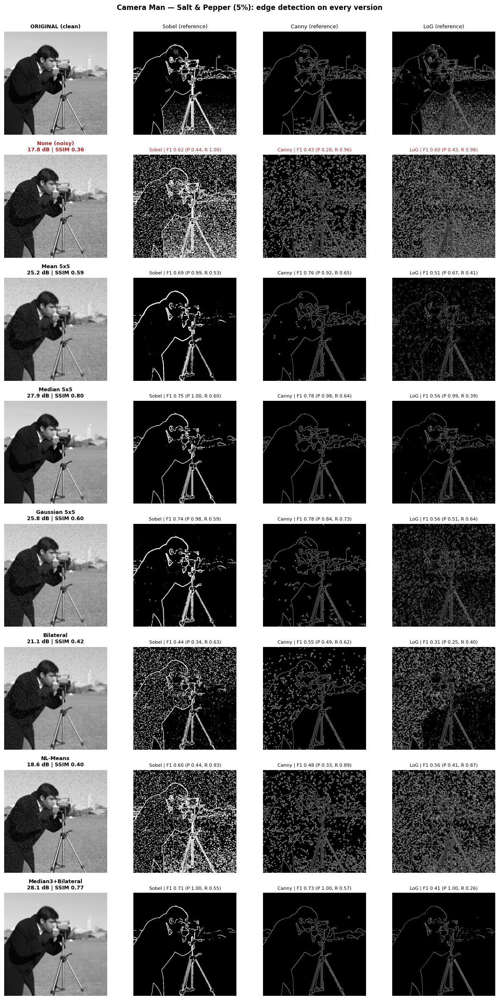

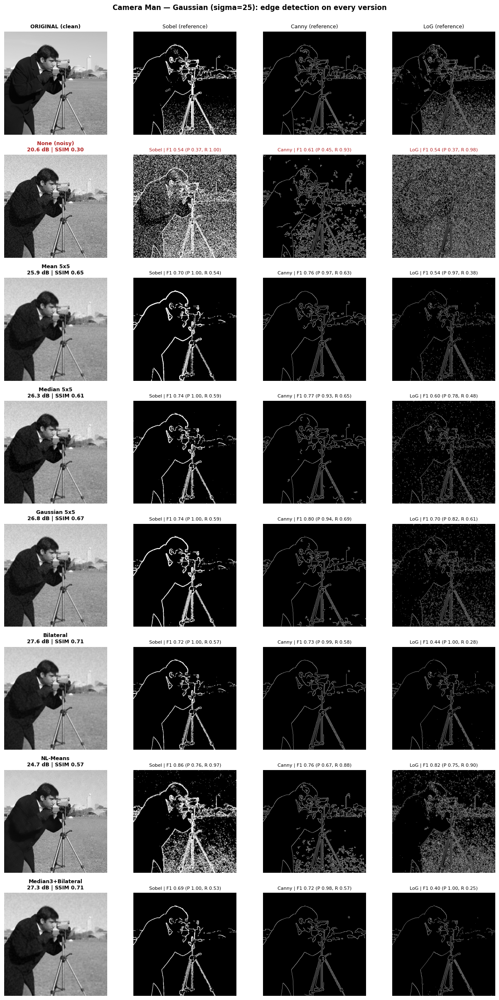

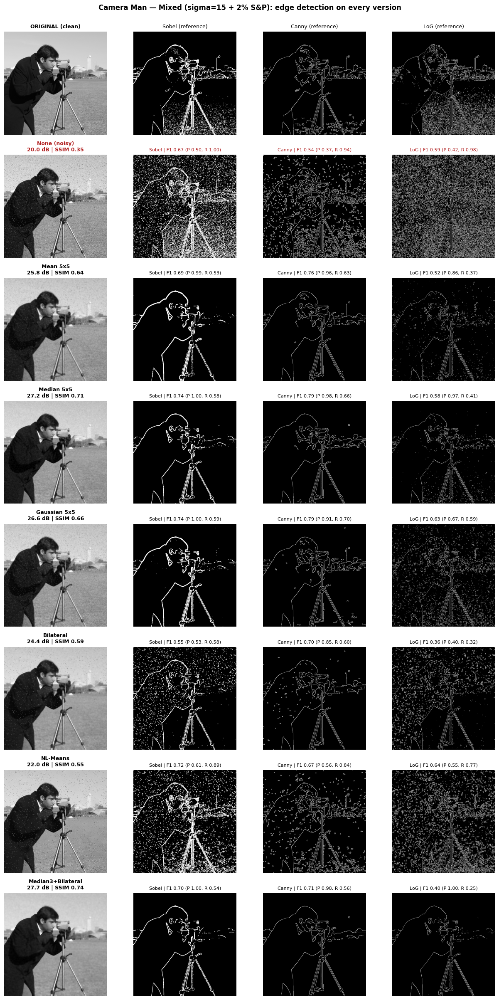

In [11]:
# Edge comparison grids (Original | Noisy | all denoised)
def elookup(img, noise, variant, det):
    r = edge_df[(edge_df.Image == img) & (edge_df.Noise == noise) & (edge_df.Filter == variant) & (edge_df.Detector == det)].iloc[0]
    return r.F1, r.Precision, r.Recall

def edge_grid(img_name, nkey):
    rows = ['Original'] + ALL_VARIANTS
    fig, axes = plt.subplots(len(rows), 1 + len(DETECTORS), figsize=(3.2 * (1 + len(DETECTORS)), 3.0 * len(rows)))
    for r, v in enumerate(rows):
        img = IMAGES[img_name] if v == 'Original' else STORE[(img_name, nkey)][v]
        axes[r][0].imshow(img, cmap='gray', vmin=0, vmax=255)
        axes[r][0].axis('off')
        if v == 'Original':
            axes[r][0].set_title('ORIGINAL (clean)', fontsize=9, fontweight='bold')
        else:
            p, s_ = qlookup(img_name, nkey, v)
            axes[r][0].set_title(f'{v}\n{p:.1f} dB | SSIM {s_:.2f}', fontsize=9, color='firebrick' if v == BASELINE else 'black', fontweight='bold')
        for c, d in enumerate(DETECTORS, start=1):
            ax = axes[r][c]; ax.axis('off')
            if v == 'Original':
                ax.imshow(ORIG_EDGES[img_name][d], cmap='gray')
                ax.set_title(f'{d} (reference)', fontsize=9)
            else:
                ax.imshow(EDGE_MAPS[(img_name, nkey, v, d)], cmap='gray')
                f1, pr, rc = elookup(img_name, nkey, v, d)
                ax.set_title(f'{d} | F1 {f1:.2f} (P {pr:.2f}, R {rc:.2f})', fontsize=8, color='firebrick' if v == BASELINE else 'black')
    fig.suptitle(f'{img_name} — {NOISE_CONFIG[nkey]["label"]}: edge detection on every version', fontweight='bold', y=1.0)
    plt.tight_layout()
    save_fig(fig, f'06_edge_grid_{img_name.replace(" ", "")}_{nkey}.png')
    plt.show()

targets = [(n, k) for n in IMAGES for k in NOISE_CONFIG] if SHOW_ALL_EDGE_GRIDS else [(first, k) for k in NOISE_CONFIG]
for n, k in targets:
    edge_grid(n, k)

## 8. Quantitative summary
Average over all images (error bars = standard deviation across images). The red-grey bar is the **no-denoising baseline**.

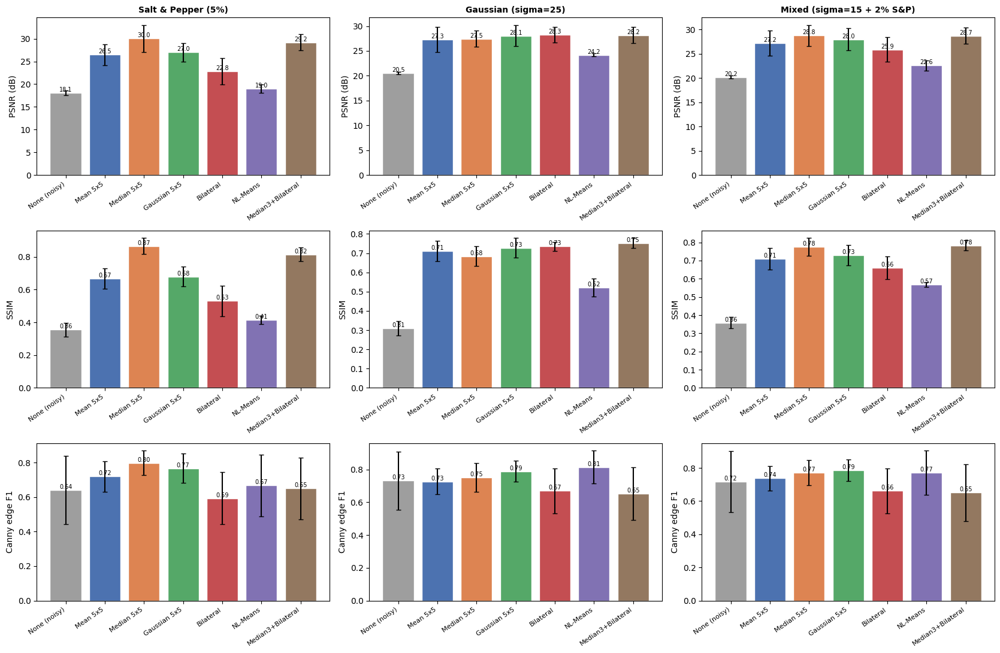

In [12]:
# PSNR / SSIM / Canny-F1 per filter per noise type
canny_df = edge_df[edge_df.Detector == 'Canny'][['Image', 'Noise', 'Filter', 'F1']]
panel = quality_df.merge(canny_df, on=['Image', 'Noise', 'Filter'])

colors = ['#9e9e9e', '#4C72B0', '#DD8452', '#55A868', '#C44E52', '#8172B3', '#937860']
fig, axes = plt.subplots(3, len(NOISE_CONFIG), figsize=(5.6 * len(NOISE_CONFIG), 11))
for c, (nkey, cfg) in enumerate(NOISE_CONFIG.items()):
    for r, (metric, label) in enumerate([('PSNR', 'PSNR (dB)'), ('SSIM', 'SSIM'), ('F1', 'Canny edge F1')]):
        g = panel[panel.Noise == nkey].groupby('Filter')[metric].agg(['mean', 'std']).reindex(ALL_VARIANTS)
        ax = axes[r][c]
        bars = ax.bar(range(len(g)), g['mean'], yerr=g['std'], color=colors, capsize=3, edgecolor='white')
        ax.set_xticks(range(len(g))); ax.set_xticklabels(g.index, rotation=35, ha='right', fontsize=8)
        ax.set_ylabel(label); ax.set_title(cfg['label'] if r == 0 else '', fontsize=10, fontweight='bold')
        for b, v in zip(bars, g['mean']):
            ax.text(b.get_x() + b.get_width() / 2, b.get_height(), f'{v:.2f}' if metric != 'PSNR' else f'{v:.1f}',
                    ha='center', va='bottom', fontsize=7)
plt.tight_layout()
save_fig(fig, '07_summary_bars.png')
plt.show()

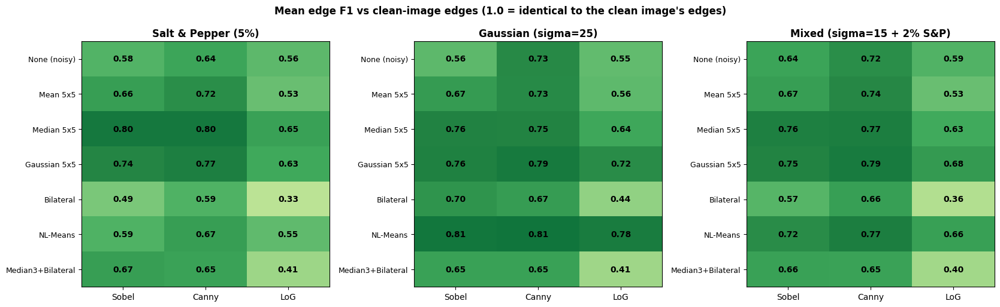

In [13]:
# Edge F1 heatmaps (filter x detector) for each noise type
fig, axes = plt.subplots(1, len(NOISE_CONFIG), figsize=(5.6 * len(NOISE_CONFIG), 5.2))
F1_TABLES = {}
for ax, (nkey, cfg) in zip(np.atleast_1d(axes), NOISE_CONFIG.items()):
    t = (edge_df[edge_df.Noise == nkey].pivot_table(index='Filter', columns='Detector', values='F1', aggfunc='mean')
         .reindex(ALL_VARIANTS)[DETECTORS])
    F1_TABLES[nkey] = t
    im = ax.imshow(t.values, cmap='YlGn', vmin=0, vmax=1, aspect='auto')
    ax.set_xticks(range(len(DETECTORS))); ax.set_xticklabels(DETECTORS)
    ax.set_yticks(range(len(t))); ax.set_yticklabels(t.index, fontsize=9)
    ax.set_title(cfg['label'], fontweight='bold')
    for i in range(t.shape[0]):
        for j in range(t.shape[1]):
            ax.text(j, i, f'{t.values[i, j]:.2f}', ha='center', va='center', fontsize=10, fontweight='bold')
fig.suptitle('Mean edge F1 vs clean-image edges (1.0 = identical to the clean image\'s edges)', fontweight='bold')
plt.tight_layout()
save_fig(fig, '08_edge_f1_heatmaps.png')
plt.show()

## 9. Hypothesis test (computed, not assumed)
*Pipeline filter* = for each (image, noise) the filter with the **highest PSNR**, chosen without looking at any edge metric.
We compare the F1 of the noisy image against the F1 of that denoised image. The verdict below is generated from the data
and will say "not supported" if the data does not support it. Failures are listed explicitly.

HYPOTHESIS: edge detection on the denoised image is closer to the clean-image edges than on the noisy image
Denoising improved edge F1 in 27/36 cases (75%) | mean F1 gain +0.088 | VERDICT: SUPPORTED

Per detector:
  Sobel : improved in 100% of cases, mean F1 gain +0.164
  Canny : improved in 67% of cases, mean F1 gain +0.065
  LoG   : improved in 58% of cases, mean F1 gain +0.033
  -> Sobel (no smoothing inside) gains the most from denoising; Canny/LoG already smooth internally, so denoising adds less.

Per noise type x detector (pipeline filter = best PSNR). Recovery = share of noise-induced F1 loss that was won back:
                      F1_noisy  F1_denoised   Gain  Recovery  WinRate
Noise       Detector                                                 
gaussian    Canny        0.732        0.759  0.027     0.102     0.50
            LoG          0.547        0.622  0.075     0.165     0.75
            Sobel        0.559        0.752  0.192     0.437     1.00
mixed       Canny      

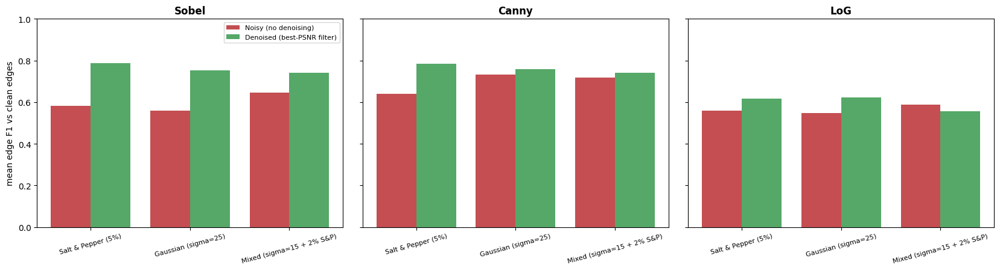

In [14]:
# Hypothesis test + best-filter analysis
eidx = edge_df.set_index(['Image', 'Noise', 'Filter', 'Detector'])['F1']
den_q = quality_df[quality_df.Filter != BASELINE]

PIPE = {}
for (img, noise), g in den_q.groupby(['Image', 'Noise']):
    PIPE[(img, noise)] = g.loc[g['PSNR'].idxmax(), 'Filter']

rows = []
for (img, noise), f in PIPE.items():
    for d in DETECTORS:
        f1n, f1d = eidx[(img, noise, BASELINE, d)], eidx[(img, noise, f, d)]
        rows.append(dict(Image=img, Noise=noise, Detector=d, PipelineFilter=f, F1_noisy=f1n, F1_denoised=f1d, Gain=f1d - f1n))
hyp_df = pd.DataFrame(rows)

def summarise_hyp(g):
    out = g.groupby(['Noise', 'Detector'])[['F1_noisy', 'F1_denoised', 'Gain']].mean()
    # Recovery = share of the F1 that noise destroyed which denoising won back (computed on the means; can be negative)
    out['Recovery'] = out.Gain / (1 - out.F1_noisy)
    out['WinRate'] = (g.Gain > 0).groupby([g.Noise, g.Detector]).mean()
    return out
HYP_SUMMARY = summarise_hyp(hyp_df)
hyp_df.to_csv(os.path.join(OUT_DIR, 'results_hypothesis.csv'), index=False)

n_total = len(hyp_df); n_win = int((hyp_df.Gain > 0).sum())
pct = 100 * n_win / n_total; mean_gain = hyp_df.Gain.mean()
if pct >= 75 and mean_gain > 0:   verdict = 'SUPPORTED'
elif pct >= 50 and mean_gain > 0: verdict = 'PARTIALLY SUPPORTED'
else:                             verdict = 'NOT SUPPORTED'

print('=' * 78)
print('HYPOTHESIS: edge detection on the denoised image is closer to the clean-image edges than on the noisy image')
print('=' * 78)
print(f'Denoising improved edge F1 in {n_win}/{n_total} cases ({pct:.0f}%) | mean F1 gain {mean_gain:+.3f} | VERDICT: {verdict}\n')

det_win = hyp_df.groupby('Detector').Gain.apply(lambda x: 100 * (x > 0).mean())
det_gain = hyp_df.groupby('Detector').Gain.mean()
print('Per detector:')
DET_VERDICT = {}
for d in DETECTORS:
    DET_VERDICT[d] = (det_win[d], det_gain[d])
    print(f'  {d:<6}: improved in {det_win[d]:.0f}% of cases, mean F1 gain {det_gain[d]:+.3f}')
if det_gain.get('Sobel', 0) > det_gain.get('Canny', 0):
    print('  -> Sobel (no smoothing inside) gains the most from denoising; Canny/LoG already smooth internally, so denoising adds less.')
else:
    print('  -> Sobel did NOT gain the most from denoising in this run - check the table before claiming otherwise.')

print('\nPer noise type x detector (pipeline filter = best PSNR). Recovery = share of noise-induced F1 loss that was won back:')
print(HYP_SUMMARY.round(3).to_string())

print('\nWhich filter did the pipeline pick (best PSNR) per noise type:')
print(hyp_df.drop_duplicates(['Image', 'Noise']).groupby(['Noise', 'PipelineFilter']).size().to_string())

bad = hyp_df[hyp_df.Gain <= 0]
print('\nCases where denoising did NOT help:' + (' none' if bad.empty else ''))
if not bad.empty:
    print(bad[['Image', 'Noise', 'Detector', 'PipelineFilter', 'F1_noisy', 'F1_denoised', 'Gain']].round(3).to_string(index=False))

# ---- every filter vs the noisy baseline
piv = edge_df.pivot_table(index=['Image', 'Noise', 'Detector'], columns='Filter', values='F1')
gain = piv.sub(piv[BASELINE], axis=0).drop(columns=BASELINE)
filt_gain = gain.groupby(['Noise', 'Detector']).mean().T
filt_win = (gain > 0).groupby(['Noise', 'Detector']).mean().T
print('\nMean F1 gain over the noisy baseline, per filter (positive = denoising helped):')
print(filt_gain.round(3).to_string())
print('\nFraction of images where the filter improved F1:')
print(filt_win.round(2).to_string())

# ---- best filter per noise type, by three different criteria
BEST = {}
print('\nBest filter per noise type (mean over images):')
for nkey in NOISE_CONFIG:
    sub_q = quality_df[(quality_df.Noise == nkey) & (quality_df.Filter != BASELINE)]
    sub_e = edge_df[(edge_df.Noise == nkey) & (edge_df.Filter != BASELINE)]
    b_psnr = sub_q.groupby('Filter').PSNR.mean().idxmax()
    b_ssim = sub_q.groupby('Filter').SSIM.mean().idxmax()
    b_f1 = sub_e.groupby('Filter').F1.mean().idxmax()
    b_f1_d = {d: sub_e[sub_e.Detector == d].groupby('Filter').F1.mean().idxmax() for d in DETECTORS}
    BEST[nkey] = dict(PSNR=b_psnr, SSIM=b_ssim, F1_all=b_f1, **{f'F1_{d}': v for d, v in b_f1_d.items()})
    print(f'  {NOISE_CONFIG[nkey]["label"]:<28} PSNR: {b_psnr:<18} SSIM: {b_ssim:<18} edge-F1 (all detectors): {b_f1}')
    print(f'  {"":<28} edge-F1 per detector: {b_f1_d}')
    if b_psnr != b_f1:
        print('  -> note: the best filter for image quality (PSNR) is NOT the best for edge detection here.')

# ---- plot
fig, axes = plt.subplots(1, len(DETECTORS), figsize=(5.6 * len(DETECTORS), 4.6), sharey=True)
for ax, d in zip(np.atleast_1d(axes), DETECTORS):
    sub = hyp_df[hyp_df.Detector == d].groupby('Noise')[['F1_noisy', 'F1_denoised']].mean().reindex(list(NOISE_CONFIG))
    x = np.arange(len(sub))
    ax.bar(x - 0.2, sub.F1_noisy, 0.4, label='Noisy (no denoising)', color='#C44E52')
    ax.bar(x + 0.2, sub.F1_denoised, 0.4, label='Denoised (best-PSNR filter)', color='#55A868')
    ax.set_xticks(x); ax.set_xticklabels([NOISE_CONFIG[k]['label'] for k in sub.index], rotation=15, fontsize=8)
    ax.set_title(d, fontweight='bold'); ax.set_ylim(0, 1)
    if d == DETECTORS[0]: ax.set_ylabel('mean edge F1 vs clean edges'); ax.legend(fontsize=8)
plt.tight_layout(); save_fig(fig, '09_hypothesis_noisy_vs_denoised.png'); plt.show()

## 10. Noise-level sweep — where does each filter break down?
The main experiment uses one noise level per type. Here the level is varied (S&P density and Gaussian sigma)
to see how quality and edge F1 degrade, and whether the best filter changes with the noise level.

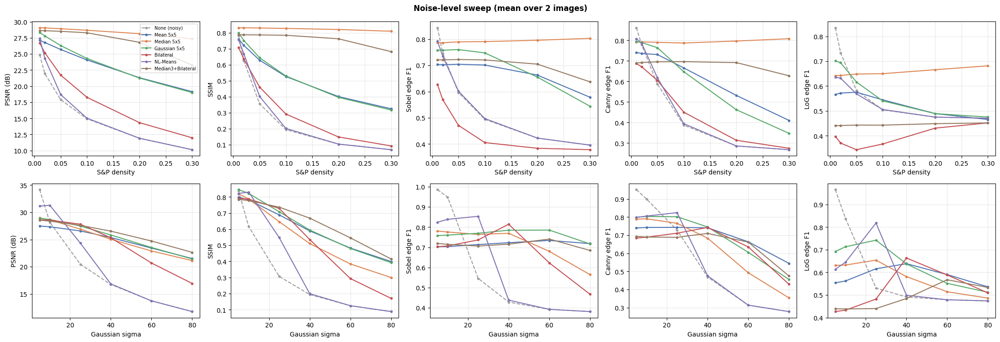


Sweep — S&P density: mean Canny F1 (rows = level, cols = filter)
Filter  None (noisy)  Mean 5x5  Median 5x5  Gaussian 5x5  Bilateral  NL-Means  Median3+Bilateral
Level                                                                                           
0.01           0.862     0.741       0.792         0.794      0.687     0.809              0.690
0.02           0.778     0.736       0.793         0.790      0.671     0.786              0.692
0.05           0.587     0.731       0.791         0.764      0.605     0.618              0.696
0.10           0.388     0.666       0.787         0.648      0.451     0.395              0.697
0.20           0.286     0.532       0.797         0.463      0.314     0.286              0.692
0.30           0.268     0.411       0.808         0.348      0.275     0.268              0.628
Sweep — S&P density: best filter by PSNR at each level
Level
0.01    Median 5x5
0.02    Median 5x5
0.05    Median 5x5
0.10    Median 5x5
0.20    Median 5x5
0.

In [15]:
#  Noise-level sweep
SWEEP = {
    'salt_pepper': dict(levels=[0.01, 0.02, 0.05, 0.10, 0.20, 0.30], make=lambda im, L, r: add_salt_pepper(im, L, r), xlabel='S&P density'),
    'gaussian':    dict(levels=[5, 10, 25, 40, 60, 80],             make=lambda im, L, r: add_gaussian(im, L, r),     xlabel='Gaussian sigma'),
}
sw_rows = []
for iname in [n for n in SWEEP_IMAGES if n in IMAGES]:
    orig = IMAGES[iname]
    for nkey, sc in SWEEP.items():
        for li, L in enumerate(sc['levels']):
            rng = np.random.default_rng([SEED, 1000 + IMG_INDEX[iname], NOISE_INDEX[nkey], li])
            noisy = sc['make'](orig, L, rng)
            _, q, e, _ = evaluate_variants(orig, noisy, DET_PARAMS[iname], ORIG_EDGES[iname])
            f1 = {(r['Filter'], r['Detector']): r['F1'] for r in e}
            for r in q:
                row = dict(Image=iname, Noise=nkey, Level=L, Filter=r['Filter'], PSNR=r['PSNR'], SSIM=r['SSIM'])
                row.update({f'F1_{d}': f1[(r['Filter'], d)] for d in DETECTORS})
                sw_rows.append(row)
sweep_df = pd.DataFrame(sw_rows)
sweep_df.to_csv(os.path.join(OUT_DIR, 'results_sweep.csv'), index=False)

metrics = [('PSNR', 'PSNR (dB)'), ('SSIM', 'SSIM')] + [(f'F1_{d}', f'{d} edge F1') for d in DETECTORS]
fig, axes = plt.subplots(len(SWEEP), len(metrics), figsize=(4.4 * len(metrics), 3.8 * len(SWEEP)))
for r, (nkey, sc) in enumerate(SWEEP.items()):
    for c, (m, lab) in enumerate(metrics):
        ax = axes[r][c]
        g = sweep_df[sweep_df.Noise == nkey].groupby(['Filter', 'Level'])[m].mean().unstack(0).reindex(columns=ALL_VARIANTS)
        for col, colr in zip(g.columns, colors):
            ax.plot(g.index, g[col], marker='o', ms=3, label=col, color=colr, ls='--' if col == BASELINE else '-')
        ax.set_xlabel(sc['xlabel']); ax.set_ylabel(lab); ax.grid(alpha=0.3)
        if r == 0 and c == 0: ax.legend(fontsize=7)
fig.suptitle(f'Noise-level sweep (mean over {sweep_df.Image.nunique()} images)', fontweight='bold')
plt.tight_layout(); save_fig(fig, '10_noise_level_sweep.png'); plt.show()

for nkey, sc in SWEEP.items():
    print(f'\nSweep — {sc["xlabel"]}: mean Canny F1 (rows = level, cols = filter)')
    print(sweep_df[sweep_df.Noise == nkey].pivot_table(index='Level', columns='Filter', values='F1_Canny', aggfunc='mean')[ALL_VARIANTS].round(3).to_string())
    print(f'Sweep — {sc["xlabel"]}: best filter by PSNR at each level')
    print(sweep_df[(sweep_df.Noise == nkey) & (sweep_df.Filter != BASELINE)].pivot_table(index='Level', columns='Filter', values='PSNR', aggfunc='mean').idxmax(axis=1).to_string())

## 11. Parameter sensitivity
All filters above use fixed parameters. This checks whether a filter lost only because its parameter was unlucky.
(Mean / Median: kernel size, Gaussian: sigma, Bilateral: sigmaColor, NL-Means: h.) Shown for S&P 5% and Gaussian sigma=25, mean over images.
Note: NL-Means `h` must grow with the noise level. The default h=15 suits moderate noise and does almost nothing at sigma>=40.

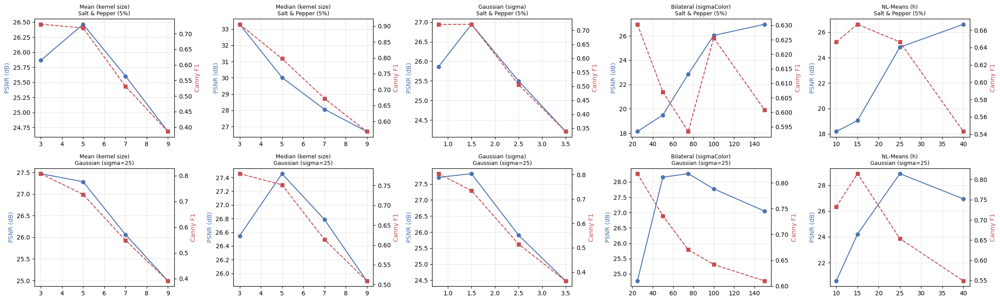


Best parameter per filter family — Salt & Pepper (5%)
  Mean (kernel size)       best PSNR at 5 (26.47 dB) | best Canny F1 at 3 (0.730)
  Median (kernel size)     best PSNR at 3 (33.29 dB) | best Canny F1 at 3 (0.906)
  Gaussian (sigma)         best PSNR at 1.5 (26.95 dB) | best Canny F1 at 1.5 (0.722)
  Bilateral (sigmaColor)   best PSNR at 150 (26.95 dB) | best Canny F1 at 25 (0.630)
  NL-Means (h)             best PSNR at 40 (26.63 dB) | best Canny F1 at 15 (0.667)

Best parameter per filter family — Gaussian (sigma=25)
  Mean (kernel size)       best PSNR at 3 (27.47 dB) | best Canny F1 at 3 (0.808)
  Median (kernel size)     best PSNR at 5 (27.46 dB) | best Canny F1 at 3 (0.780)
  Gaussian (sigma)         best PSNR at 1.5 (27.82 dB) | best Canny F1 at 0.8 (0.804)
  Bilateral (sigmaColor)   best PSNR at 75 (28.27 dB) | best Canny F1 at 25 (0.818)
  NL-Means (h)             best PSNR at 25 (28.90 dB) | best Canny F1 at 15 (0.814)


In [16]:
# Parameter sensitivity
def mk_blur(k):   return lambda im: cv2.blur(im, (k, k))
def mk_median(k): return lambda im: cv2.medianBlur(im, k)
def mk_gauss(s):  return lambda im: cv2.GaussianBlur(im, (0, 0), s)
def mk_bilat(sc): return lambda im: cv2.bilateralFilter(im, 9, sc, 75)
def mk_nlm(h):    return lambda im: cv2.fastNlMeansDenoising(im, None, h=h, templateWindowSize=7, searchWindowSize=21)

SENS = {
    'Mean (kernel size)':       [(k, mk_blur(k)) for k in [3, 5, 7, 9]],
    'Median (kernel size)':     [(k, mk_median(k)) for k in [3, 5, 7, 9]],
    'Gaussian (sigma)':         [(s, mk_gauss(s)) for s in [0.8, 1.5, 2.5, 3.5]],
    'Bilateral (sigmaColor)':   [(s, mk_bilat(s)) for s in [25, 50, 75, 100, 150]],
    'NL-Means (h)':             [(h, mk_nlm(h)) for h in [10, 15, 25, 40]],
}
se_rows = []
for nkey in ['salt_pepper', 'gaussian']:
    for fam, opts in SENS.items():
        for val, fn in opts:
            for iname in IMAGES:
                noisy = get_noisy(iname, nkey)
                out = fn(noisy)
                e = detect('Canny', out, DET_PARAMS[iname])
                se_rows.append(dict(Noise=nkey, Family=fam, Value=val, Image=iname, PSNR=psnr(IMAGES[iname], out),
                                    F1_Canny=edge_scores(e, ORIG_EDGES[iname]['Canny'])['F1']))
sens_df = pd.DataFrame(se_rows)
sens_df.to_csv(os.path.join(OUT_DIR, 'results_sensitivity.csv'), index=False)

fig, axes = plt.subplots(2, len(SENS), figsize=(4.6 * len(SENS), 7))
for r, nkey in enumerate(['salt_pepper', 'gaussian']):
    for c, fam in enumerate(SENS):
        g = sens_df[(sens_df.Noise == nkey) & (sens_df.Family == fam)].groupby('Value')[['PSNR', 'F1_Canny']].mean()
        ax = axes[r][c]; ax2 = ax.twinx()
        ax.plot(g.index, g.PSNR, 'o-', color='#4C72B0'); ax2.plot(g.index, g.F1_Canny, 's--', color='#C44E52')
        ax.set_title(f'{fam}\n{NOISE_CONFIG[nkey]["label"]}', fontsize=9)
        ax.set_ylabel('PSNR (dB)', color='#4C72B0'); ax2.set_ylabel('Canny F1', color='#C44E52'); ax.grid(alpha=0.3)
plt.tight_layout(); save_fig(fig, '11_parameter_sensitivity.png'); plt.show()

SENS_BEST = {}
for nkey in ['salt_pepper', 'gaussian']:
    print(f'\nBest parameter per filter family — {NOISE_CONFIG[nkey]["label"]}')
    for fam in SENS:
        g = sens_df[(sens_df.Noise == nkey) & (sens_df.Family == fam)].groupby('Value')[['PSNR', 'F1_Canny']].mean()
        SENS_BEST[(nkey, fam)] = (g.PSNR.idxmax(), g.F1_Canny.idxmax())
        print(f'  {fam:<24} best PSNR at {g.PSNR.idxmax():g} ({g.PSNR.max():.2f} dB) | best Canny F1 at {g.F1_Canny.idxmax():g} ({g.F1_Canny.max():.3f})')

## 12. Real-world noisy images
Put paths of real noisy photos (low-light, high-ISO, old scans, CCTV frames, medical images…) in `REAL_IMAGES`.
For each one this cell runs **all six denoisers** and the **three edge detectors** on the raw image and on every denoised version.

---
A real photo has no clean ground truth, so PSNR/F1 are not available. Instead we use measurements that need no reference:
* **Estimated noise sigma** (Immerkaer's method) — lower after denoising = noise removed.
* **Edge density ratio** — edge pixels divided by the typical edge density of the *clean* reference images (same thresholds). About 1.0 = plausible; much greater than 1 = noise is being detected as edges; much less than 1 = real edges were blurred away.
* **Speck count** — tiny isolated edge fragments (≤4 px). Secondary: when the raw image is almost all edge, specks merge into large blobs and the count is misleading, so read it together with the density ratio.
---
#### Warning: low noise sigma alone can also mean "blurred everything". Look at the images too: real edges should survive.

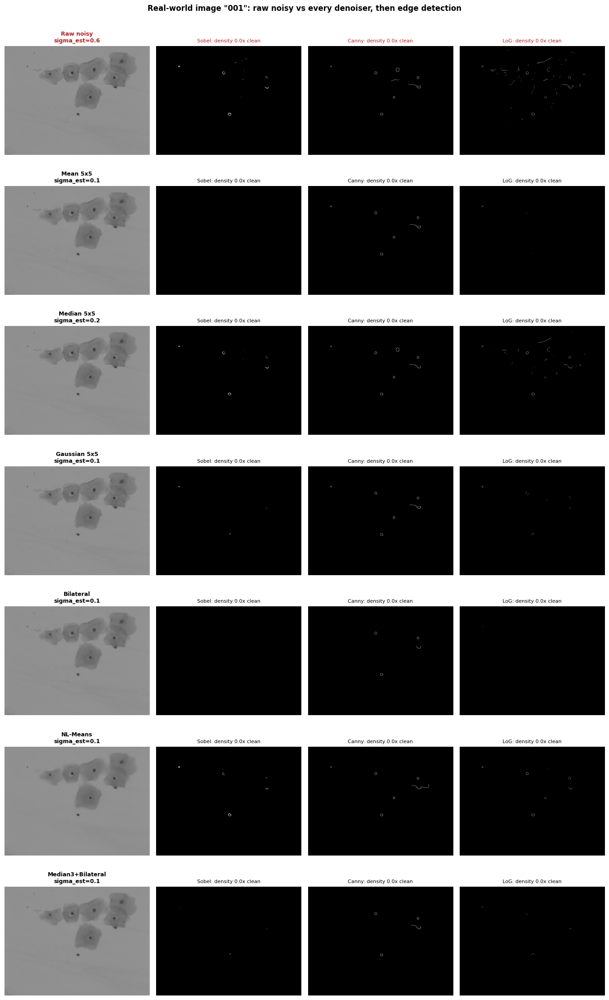

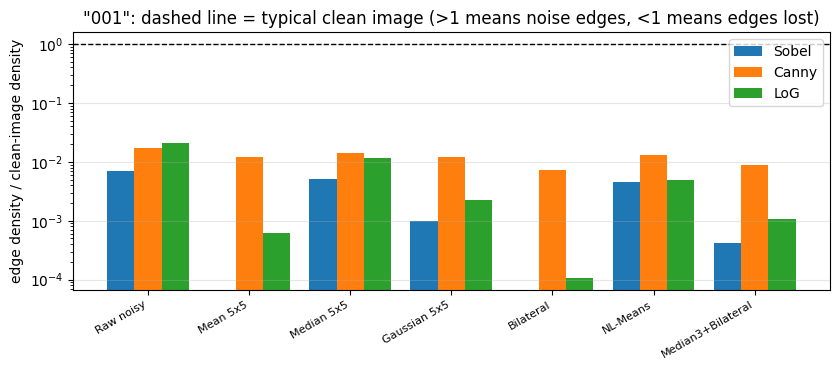

                   NoiseSigmaEst  Sobel_density  Sobel_dens_ratio  Sobel_specks  Canny_density  Canny_dens_ratio  Canny_specks  LoG_density  LoG_dens_ratio  LoG_specks
Version                                                                                                                                                                
Raw noisy                  0.577          0.001             0.007             9          0.001             0.017             0        0.002           0.021         102
Mean 5x5                   0.142          0.000             0.000             0          0.001             0.012             0        0.000           0.001           5
Median 5x5                 0.165          0.001             0.005             3          0.001             0.014             0        0.001           0.011          21
Gaussian 5x5               0.148          0.000             0.001             2          0.001             0.012             0        0.000           0.002     

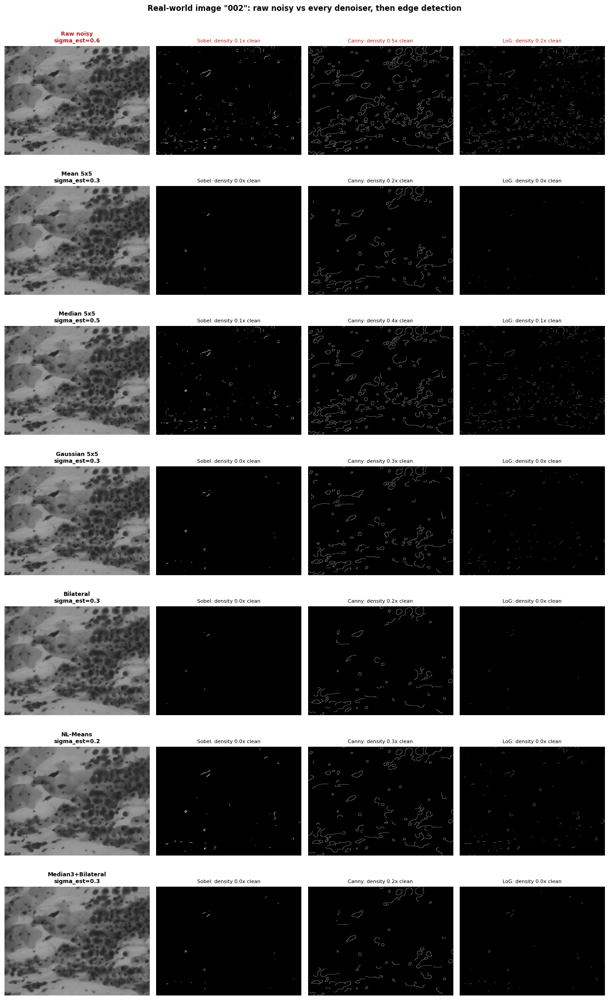

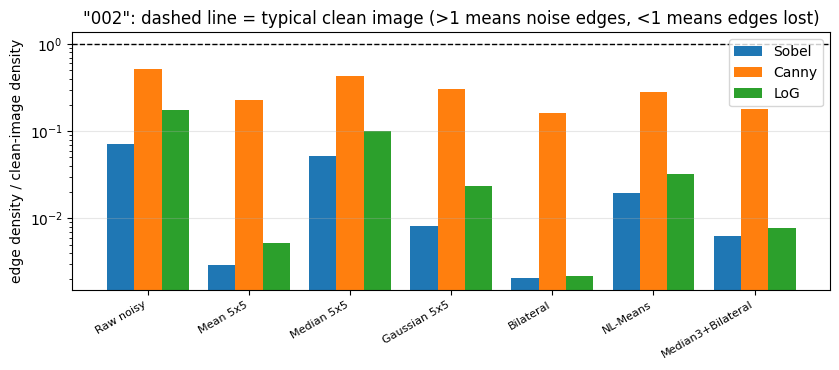

                   NoiseSigmaEst  Sobel_density  Sobel_dens_ratio  Sobel_specks  Canny_density  Canny_dens_ratio  Canny_specks  LoG_density  LoG_dens_ratio  LoG_specks
Version                                                                                                                                                                
Raw noisy                  0.566          0.007             0.072           133          0.027             0.514             0        0.014           0.175         836
Mean 5x5                   0.279          0.000             0.003             5          0.012             0.226             1        0.000           0.005          40
Median 5x5                 0.455          0.005             0.051            67          0.023             0.428             1        0.008           0.099         312
Gaussian 5x5               0.281          0.001             0.008             1          0.016             0.308             1        0.002           0.024     

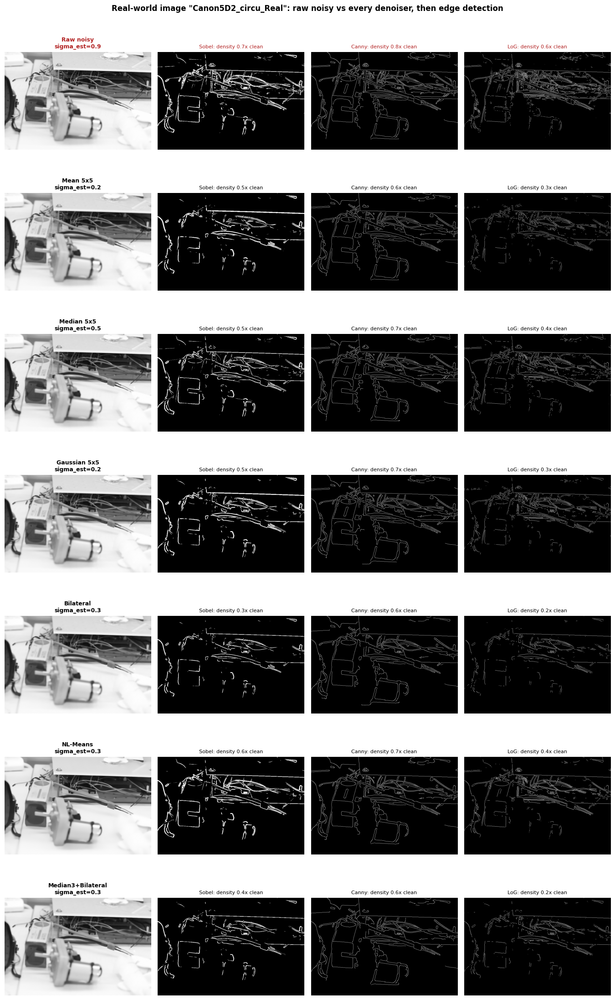

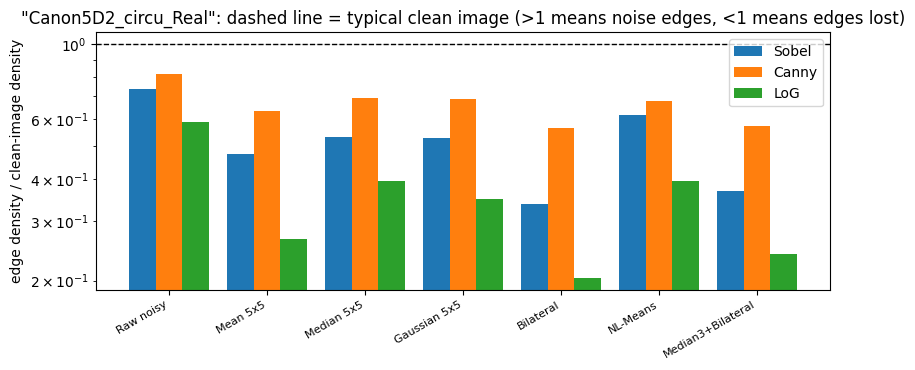

                   NoiseSigmaEst  Sobel_density  Sobel_dens_ratio  Sobel_specks  Canny_density  Canny_dens_ratio  Canny_specks  LoG_density  LoG_dens_ratio  LoG_specks
Version                                                                                                                                                                
Raw noisy                  0.921          0.074             0.738           223          0.043             0.817            28        0.046           0.588         543
Mean 5x5                   0.233          0.047             0.474            36          0.034             0.634            13        0.021           0.265         344
Median 5x5                 0.531          0.053             0.530            90          0.037             0.694            12        0.031           0.394         391
Gaussian 5x5               0.235          0.053             0.529            38          0.036             0.690            15        0.027           0.349     

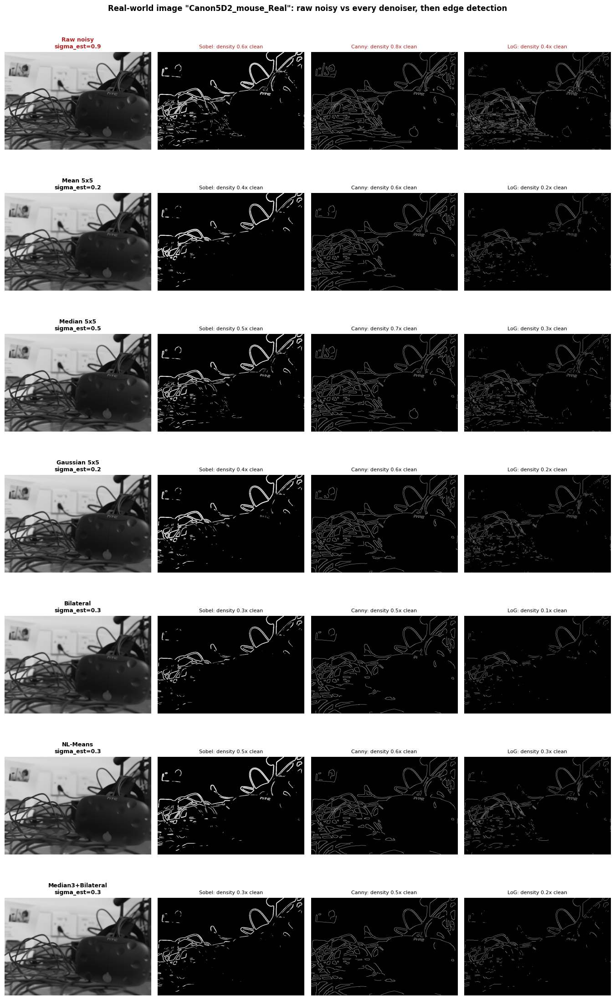

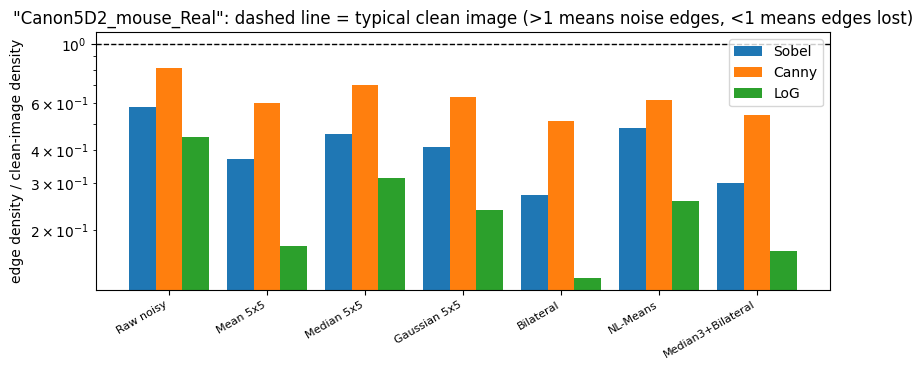

                   NoiseSigmaEst  Sobel_density  Sobel_dens_ratio  Sobel_specks  Canny_density  Canny_dens_ratio  Canny_specks  LoG_density  LoG_dens_ratio  LoG_specks
Version                                                                                                                                                                
Raw noisy                  0.856          0.058             0.582           116          0.043             0.811             7        0.035           0.449         467
Mean 5x5                   0.225          0.037             0.368            17          0.032             0.599             6        0.014           0.174         211
Median 5x5                 0.476          0.046             0.461            61          0.037             0.703             4        0.024           0.312         289
Gaussian 5x5               0.226          0.041             0.411            31          0.033             0.634             3        0.019           0.237     

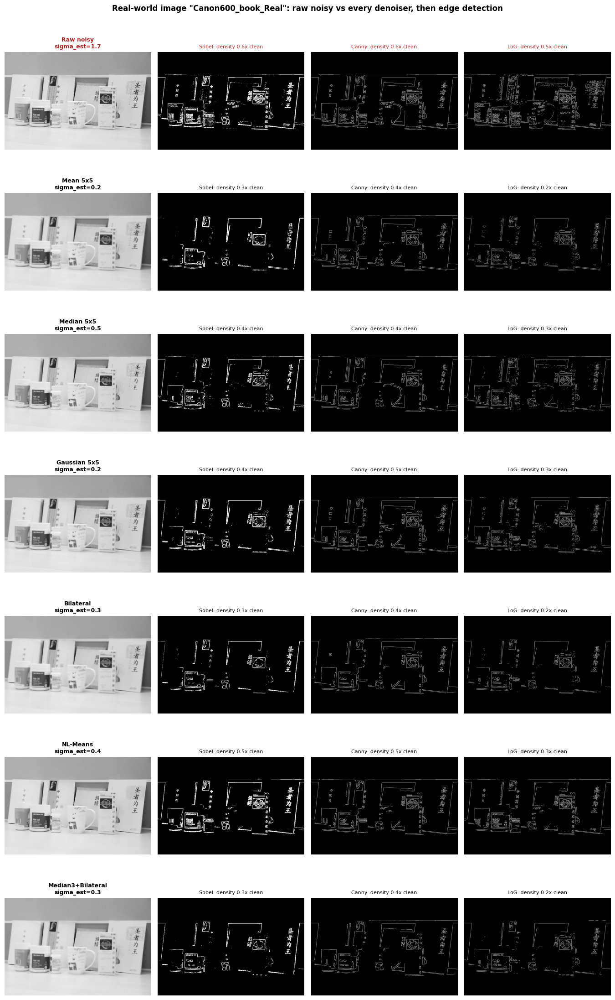

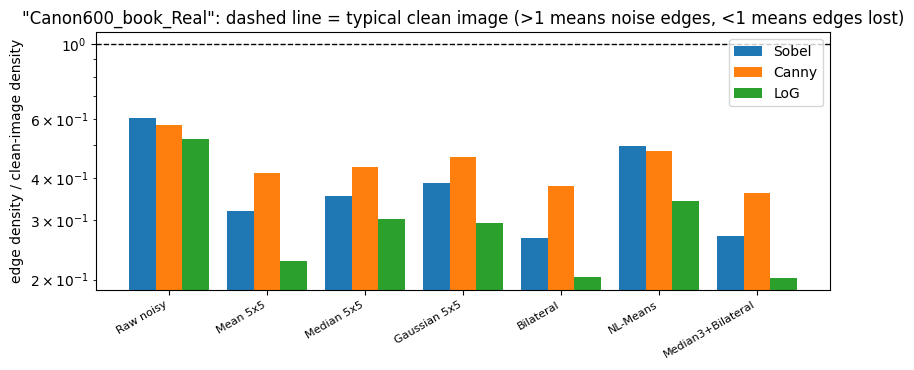

                   NoiseSigmaEst  Sobel_density  Sobel_dens_ratio  Sobel_specks  Canny_density  Canny_dens_ratio  Canny_specks  LoG_density  LoG_dens_ratio  LoG_specks
Version                                                                                                                                                                
Raw noisy                  1.674          0.060             0.605           185          0.030             0.575             8        0.041           0.521         552
Mean 5x5                   0.222          0.032             0.319            58          0.022             0.415             5        0.018           0.227         167
Median 5x5                 0.456          0.035             0.354            64          0.023             0.432             8        0.024           0.303         295
Gaussian 5x5               0.216          0.039             0.387            56          0.024             0.463             7        0.023           0.295     

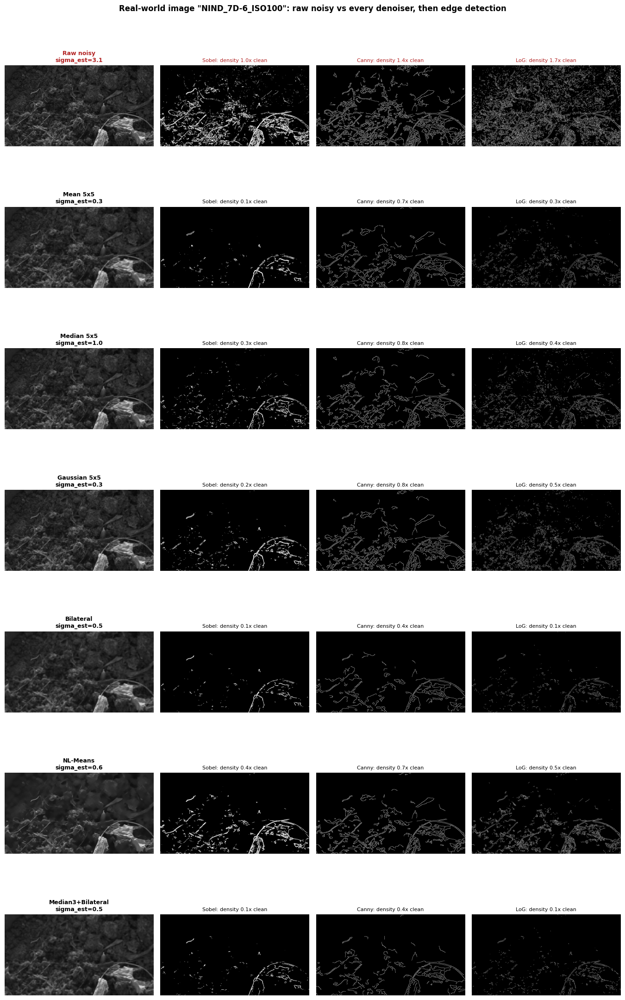

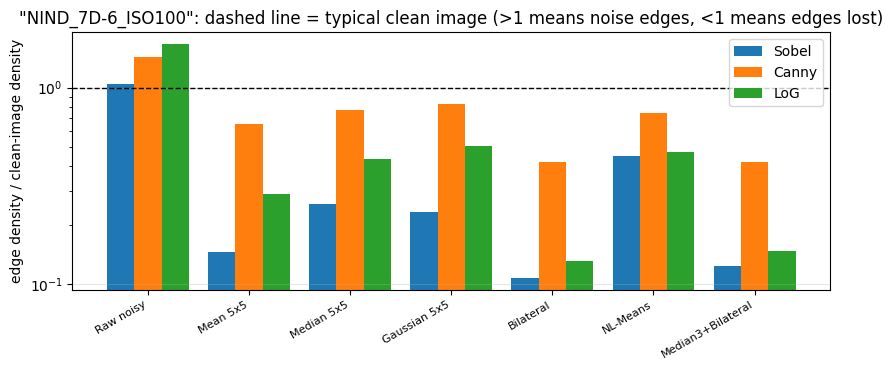

                   NoiseSigmaEst  Sobel_density  Sobel_dens_ratio  Sobel_specks  Canny_density  Canny_dens_ratio  Canny_specks  LoG_density  LoG_dens_ratio  LoG_specks
Version                                                                                                                                                                
Raw noisy                  3.072          0.105             1.046          1355          0.075             1.428            14        0.131           1.666        4241
Mean 5x5                   0.315          0.015             0.146            97          0.035             0.657             2        0.023           0.288         864
Median 5x5                 1.010          0.025             0.255           271          0.041             0.773             5        0.034           0.436        1182
Gaussian 5x5               0.309          0.023             0.233           157          0.044             0.825             5        0.039           0.503     

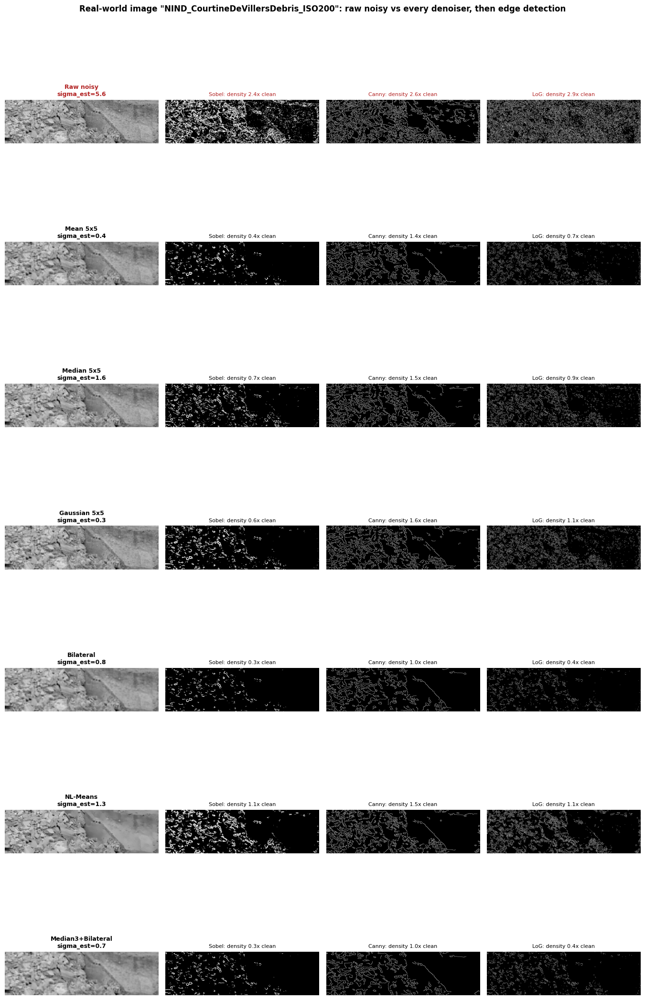

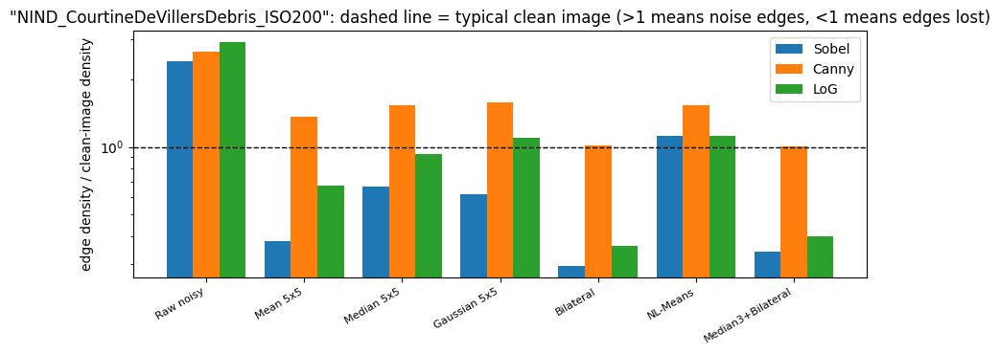

                   NoiseSigmaEst  Sobel_density  Sobel_dens_ratio  Sobel_specks  Canny_density  Canny_dens_ratio  Canny_specks  LoG_density  LoG_dens_ratio  LoG_specks
Version                                                                                                                                                                
Raw noisy                  5.562          0.240             2.401          1607          0.140             2.648            55        0.229           2.926        1920
Mean 5x5                   0.354          0.038             0.383           162          0.072             1.357            13        0.053           0.671        1027
Median 5x5                 1.569          0.067             0.669           244          0.081             1.534            18        0.073           0.932        1122
Gaussian 5x5               0.332          0.061             0.614           198          0.083             1.576            17        0.086           1.098     

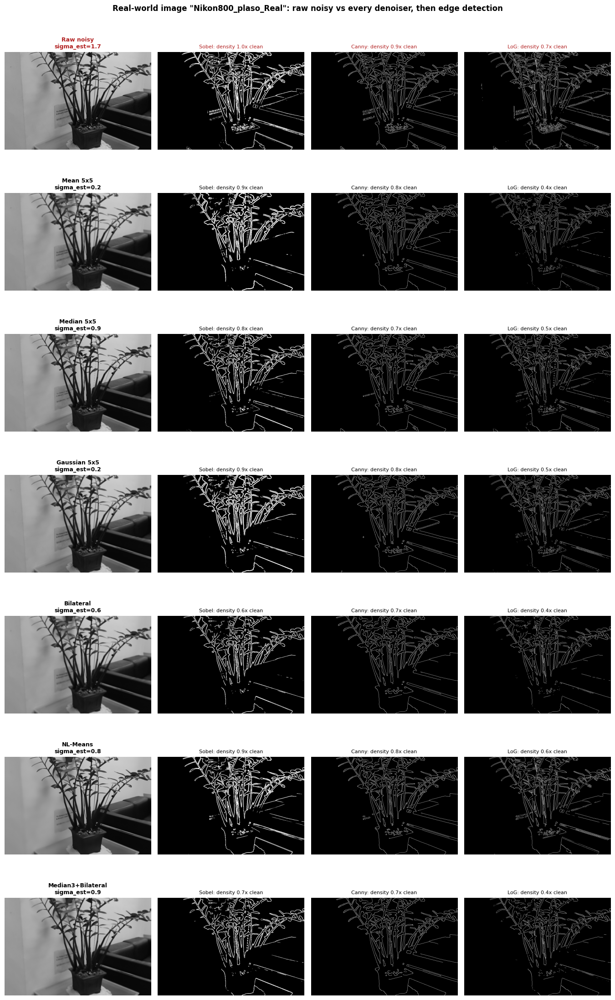

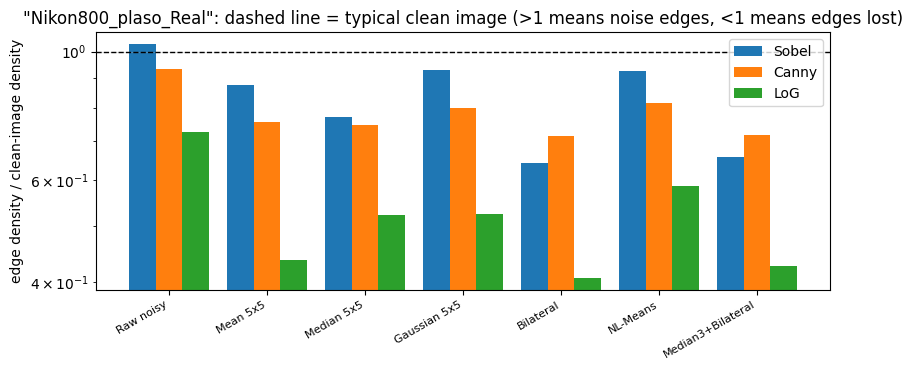

                   NoiseSigmaEst  Sobel_density  Sobel_dens_ratio  Sobel_specks  Canny_density  Canny_dens_ratio  Canny_specks  LoG_density  LoG_dens_ratio  LoG_specks
Version                                                                                                                                                                
Raw noisy                  1.719          0.103             1.031           197          0.049             0.935            39        0.057           0.726         453
Mean 5x5                   0.237          0.088             0.877            48          0.040             0.755            34        0.034           0.437         320
Median 5x5                 0.946          0.077             0.772           106          0.039             0.747            25        0.041           0.523         294
Gaussian 5x5               0.232          0.093             0.930            50          0.042             0.799            31        0.041           0.524     

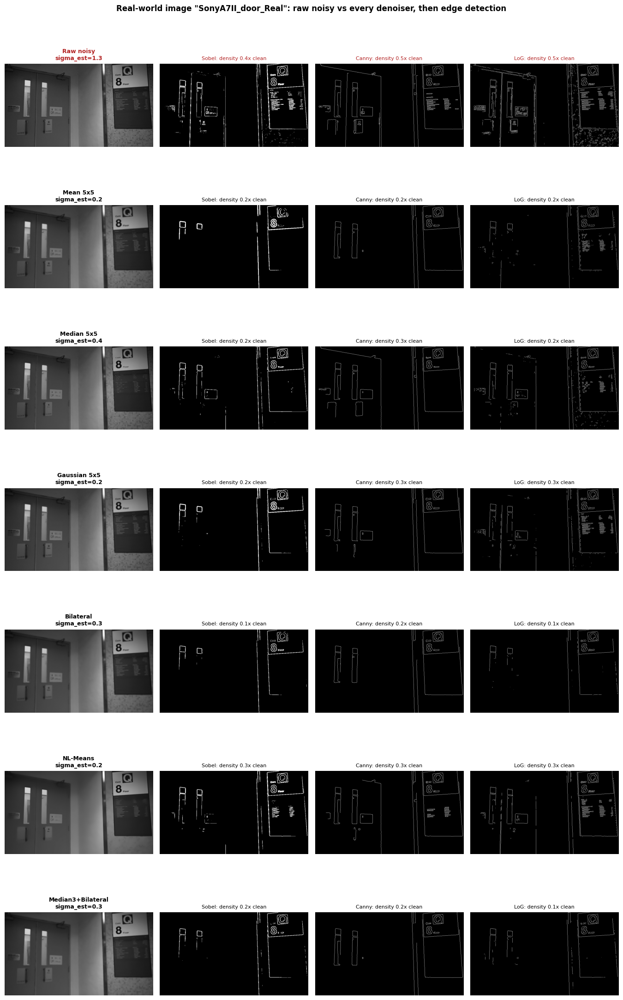

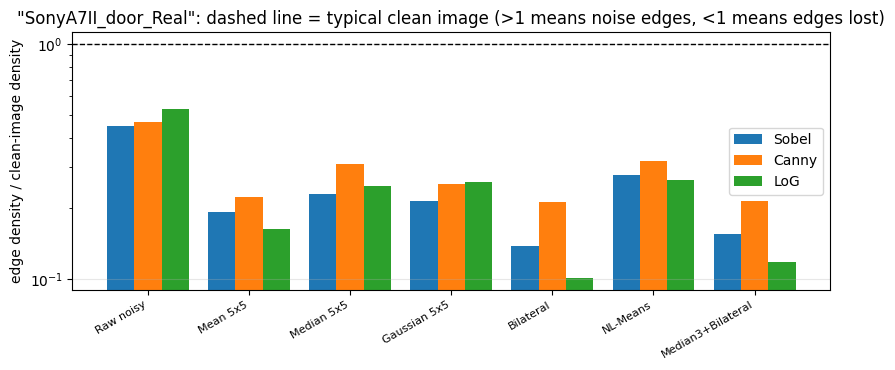

                   NoiseSigmaEst  Sobel_density  Sobel_dens_ratio  Sobel_specks  Canny_density  Canny_dens_ratio  Canny_specks  LoG_density  LoG_dens_ratio  LoG_specks
Version                                                                                                                                                                
Raw noisy                  1.336          0.045             0.450           219          0.025             0.464             1        0.042           0.531         554
Mean 5x5                   0.236          0.019             0.193            16          0.012             0.223             0        0.013           0.164          89
Median 5x5                 0.419          0.023             0.231            26          0.016             0.309             1        0.019           0.248         257
Gaussian 5x5               0.235          0.021             0.215            16          0.013             0.254             1        0.020           0.258     

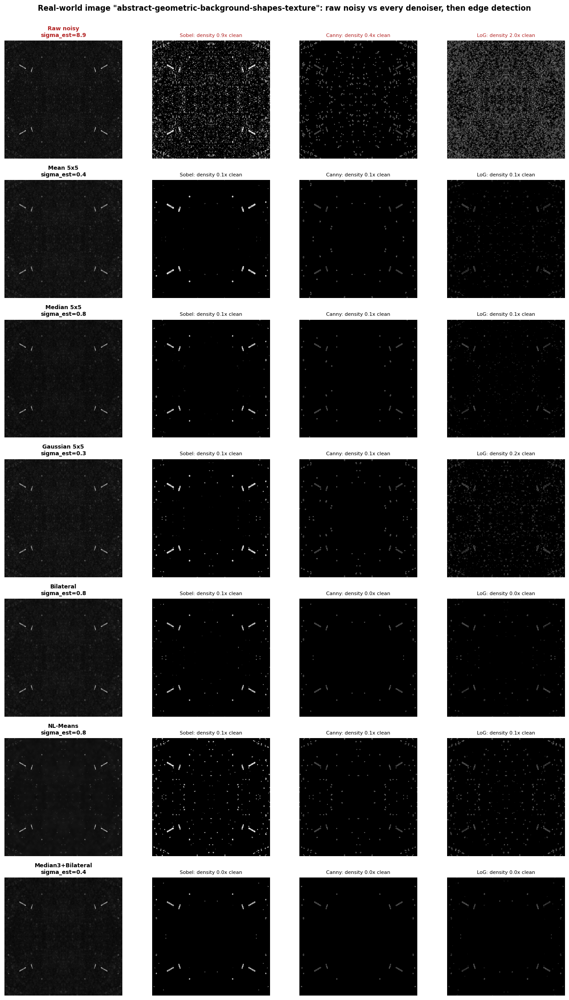

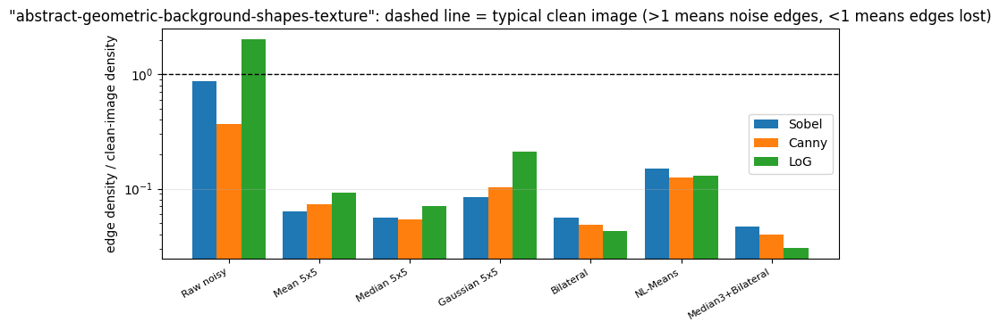

                   NoiseSigmaEst  Sobel_density  Sobel_dens_ratio  Sobel_specks  Canny_density  Canny_dens_ratio  Canny_specks  LoG_density  LoG_dens_ratio  LoG_specks
Version                                                                                                                                                                
Raw noisy                  8.886          0.087             0.871          6835          0.019             0.368            11        0.159           2.026       15084
Mean 5x5                   0.392          0.006             0.063            46          0.004             0.073             4        0.007           0.093         992
Median 5x5                 0.833          0.006             0.056            70          0.003             0.054             0        0.006           0.071         804
Gaussian 5x5               0.314          0.008             0.084            87          0.005             0.102             5        0.016           0.210     

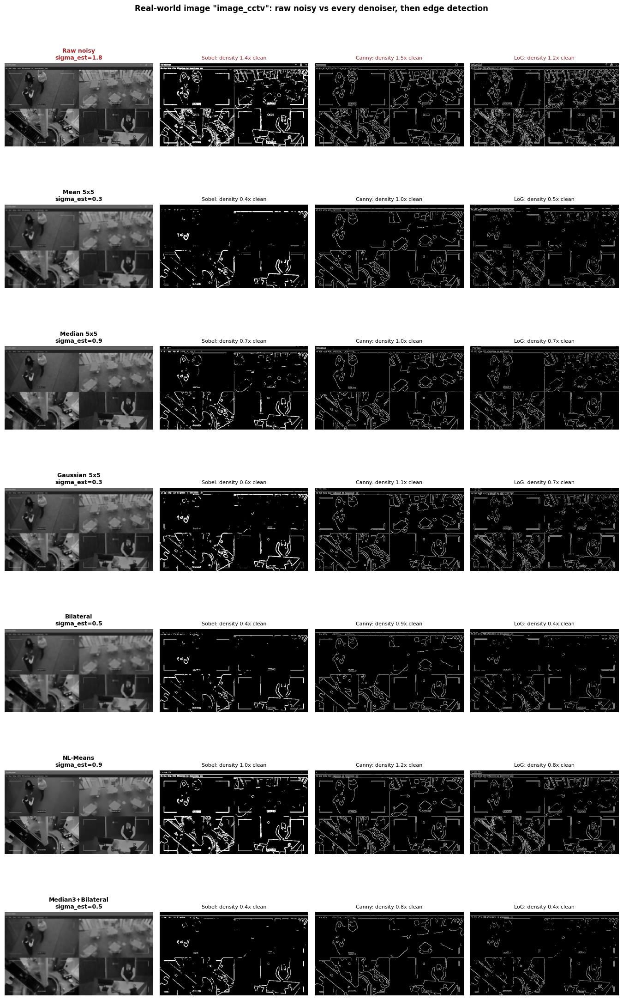

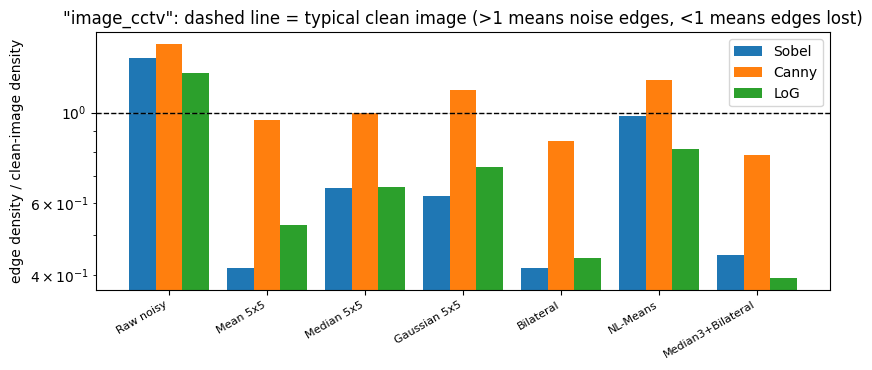

                   NoiseSigmaEst  Sobel_density  Sobel_dens_ratio  Sobel_specks  Canny_density  Canny_dens_ratio  Canny_specks  LoG_density  LoG_dens_ratio  LoG_specks
Version                                                                                                                                                                
Raw noisy                  1.811          0.136             1.359           203          0.078             1.474            10        0.098           1.249         663
Mean 5x5                   0.284          0.042             0.416            87          0.051             0.959             3        0.041           0.529         346
Median 5x5                 0.865          0.065             0.653           125          0.053             0.999             6        0.052           0.657         319
Gaussian 5x5               0.279          0.063             0.625            72          0.060             1.137             6        0.058           0.735     

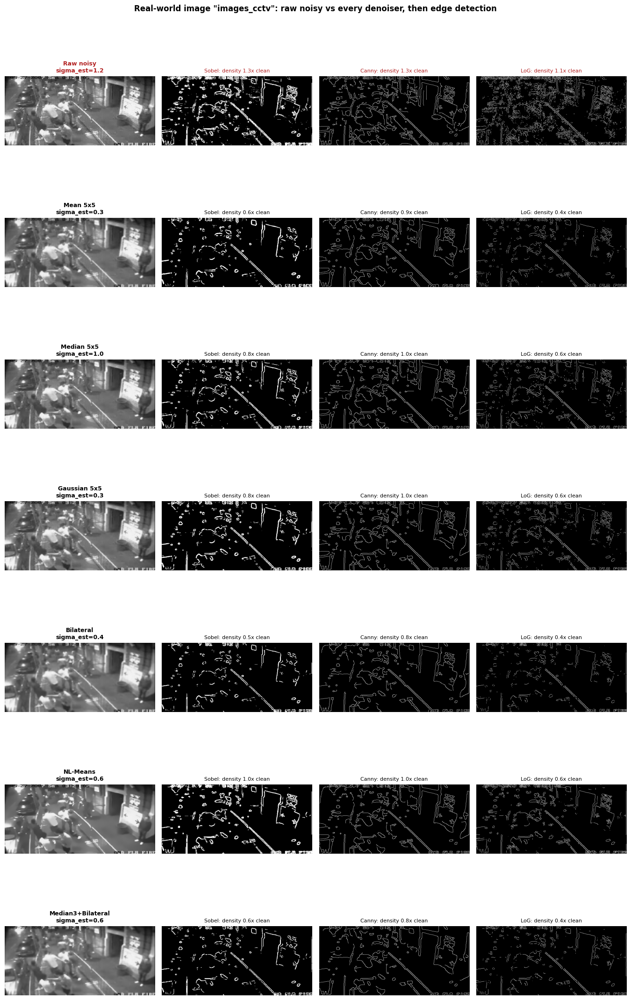

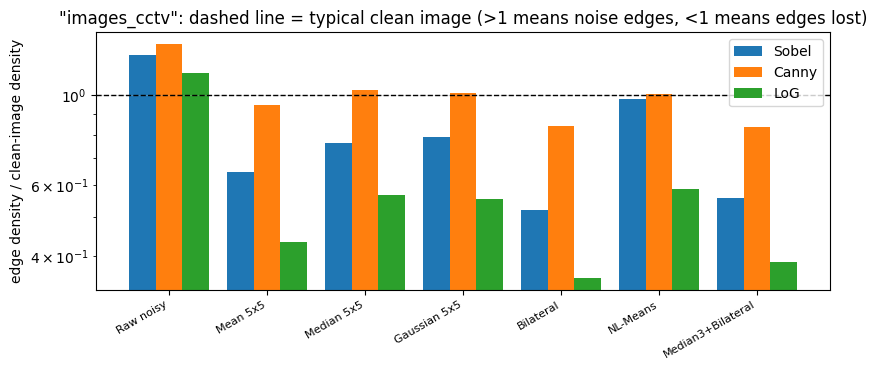

                   NoiseSigmaEst  Sobel_density  Sobel_dens_ratio  Sobel_specks  Canny_density  Canny_dens_ratio  Canny_specks  LoG_density  LoG_dens_ratio  LoG_specks
Version                                                                                                                                                                
Raw noisy                  1.224          0.126             1.259           341          0.071             1.341            34        0.089           1.134        1298
Mean 5x5                   0.294          0.065             0.646            56          0.050             0.947            24        0.034           0.432         253
Median 5x5                 1.019          0.076             0.765            74          0.055             1.032            29        0.044           0.567         341
Gaussian 5x5               0.294          0.079             0.790            52          0.054             1.015            14        0.043           0.555     

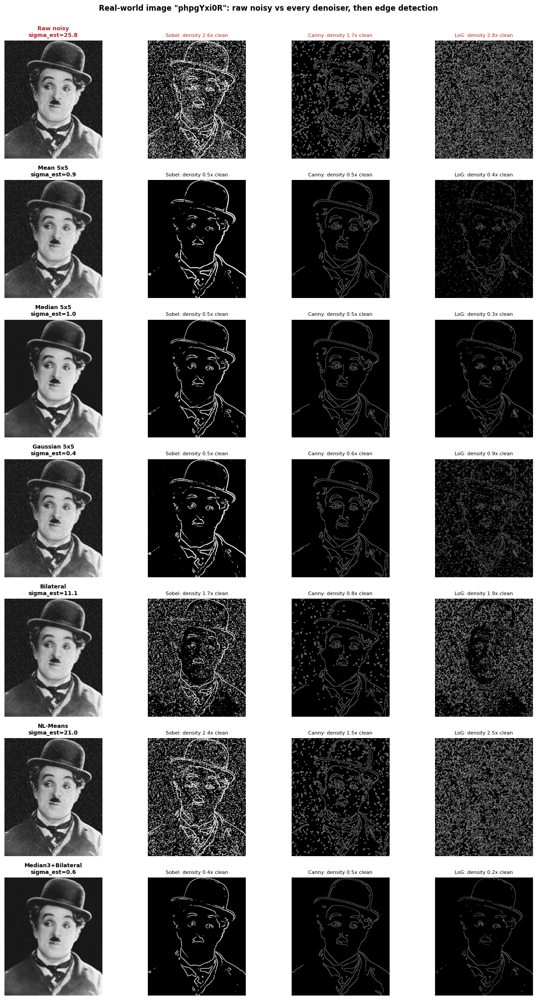

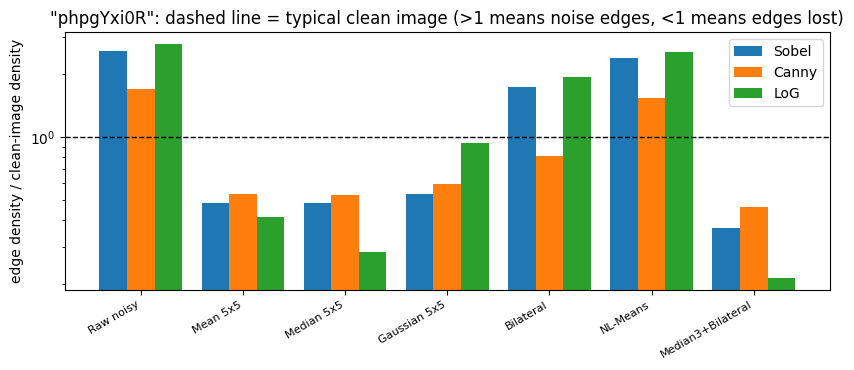

                   NoiseSigmaEst  Sobel_density  Sobel_dens_ratio  Sobel_specks  Canny_density  Canny_dens_ratio  Canny_specks  LoG_density  LoG_dens_ratio  LoG_specks
Version                                                                                                                                                                
Raw noisy                 25.814          0.257             2.566           455          0.089             1.684            59        0.218           2.775        1399
Mean 5x5                   0.885          0.049             0.486            92          0.028             0.536             8        0.033           0.415        1964
Median 5x5                 1.005          0.048             0.483            59          0.028             0.530            10        0.022           0.283         150
Gaussian 5x5               0.388          0.054             0.536           114          0.032             0.599            13        0.073           0.937     

In [17]:
# Real-world noisy image analysis

REAL_IMAGES = [
    # {'name': 'night_street', 'noisy': '/kaggle/input/my-noisy-images/night_street.jpg'},
]
# OR point to a folder: every image inside is analysed (easier than listing files one by one)
REAL_IMAGE_DIR = '/kaggle/input/datasets/almutalem/real-images'            # e.g. '/kaggle/input/my-noisy-images'
if REAL_IMAGE_DIR and os.path.isdir(REAL_IMAGE_DIR):
    for fn_ in sorted(os.listdir(REAL_IMAGE_DIR)):
        if fn_.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp', '.tif', '.tiff')):
            REAL_IMAGES.append(dict(name=os.path.splitext(fn_)[0], noisy=os.path.join(REAL_IMAGE_DIR, fn_), clean=None))

REAL_MAX_SIDE = 800          # larger images are downscaled to this (keeps NL-Means fast)
SPECK_MAX_AREA = 4

def load_gray_any(path, max_side=REAL_MAX_SIDE):
    img = cv2.imread(path, cv2.IMREAD_COLOR)
    if img is None:
        raise FileNotFoundError(path)
    g = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    s = max(g.shape)
    if s > max_side:
        f = max_side / s
        g = cv2.resize(g, (int(g.shape[1] * f), int(g.shape[0] * f)), interpolation=cv2.INTER_AREA)
    return g

def estimate_noise_sigma(gray):
    """Immerkaer (1996) fast noise-sigma estimate; no reference image needed."""
    H, W = gray.shape
    M = np.array([[1, -2, 1], [-2, 4, -2], [1, -2, 1]], np.float64)
    conv = cv2.filter2D(gray.astype(np.float64), -1, M)[1:-1, 1:-1]
    return float(np.sqrt(np.pi / 2) * np.abs(conv).sum() / (6.0 * (W - 2) * (H - 2)))

def speck_count(edge, max_area=SPECK_MAX_AREA):
    n, _, stats, _ = cv2.connectedComponentsWithStats((edge > 0).astype(np.uint8), connectivity=8)
    return int((stats[1:, cv2.CC_STAT_AREA] <= max_area).sum()) if n > 1 else 0

GLOBAL_PARAMS = {k: float(np.median([DET_PARAMS[n][k] for n in DET_PARAMS])) for k in next(iter(DET_PARAMS.values()))}
CLEAN_DENSITY = {d: float(np.median([ORIG_EDGES[n][d].mean() / 255 for n in IMAGES])) for d in DETECTORS}   # typical clean edge density

def analyse_real(name, noisy):
    variants = {'Raw noisy': noisy}
    for fname, fn in FILTERS.items():
        variants[fname] = fn(noisy)
    emaps = {(v, d): detect(d, im, GLOBAL_PARAMS) for v, im in variants.items() for d in DETECTORS}

    rows = []
    for v, im in variants.items():
        r = dict(Version=v, NoiseSigmaEst=estimate_noise_sigma(im))
        for d in DETECTORS:
            r[f'{d}_density'] = emaps[(v, d)].mean() / 255
            r[f'{d}_dens_ratio'] = r[f'{d}_density'] / CLEAN_DENSITY[d]
            r[f'{d}_specks'] = speck_count(emaps[(v, d)])
        rows.append(r)
        
    res = pd.DataFrame(rows).set_index('Version')
    res.to_csv(os.path.join(OUT_DIR, f'real_{name}_metrics.csv'))

    # --- Figure: rows = versions, cols = image + detectors
    nr = len(variants)
    fig, axes = plt.subplots(nr, 1 + len(DETECTORS), figsize=(3.4 * (1 + len(DETECTORS)), 3.2 * nr))
    for r_i, (v, im) in enumerate(variants.items()):
        axes[r_i][0].imshow(im, cmap='gray', vmin=0, vmax=255)
        axes[r_i][0].axis('off')
        axes[r_i][0].set_title(
            f'{v}\nsigma_est={res.loc[v, "NoiseSigmaEst"]:.1f}', 
            fontsize=9, fontweight='bold',
            color='firebrick' if v == 'Raw noisy' else 'black'
        )
        for c, d in enumerate(DETECTORS, start=1):
            ax = axes[r_i][c]
            ax.imshow(emaps[(v, d)], cmap='gray')
            ax.axis('off')
            ax.set_title(
                f'{d}: density {res.loc[v, d + "_dens_ratio"]:.1f}x clean', 
                fontsize=8,
                color='firebrick' if v == 'Raw noisy' else 'black'
            )
            
    fig.suptitle(f'Real-world image "{name}": raw noisy vs every denoiser, then edge detection', fontweight='bold', y=1.0)
    plt.tight_layout()
    save_fig(fig, f'12_real_{name}_edges.png')
    plt.show()

    # --- Figure: edge density relative to the clean reference
    fig, ax = plt.subplots(figsize=(8.5, 3.8))
    w = 0.27
    for i, d in enumerate(DETECTORS):
        ax.bar(np.arange(len(res)) + (i - 1) * w, res[f'{d}_dens_ratio'], w, label=d)
    ax.axhline(1.0, color='k', ls='--', lw=1)
    ax.set_xticks(range(len(res)))
    ax.set_xticklabels(res.index, rotation=30, ha='right', fontsize=8)
    ax.set_ylabel('edge density / clean-image density')
    ax.set_yscale('log')
    ax.legend()
    ax.grid(alpha=0.3, axis='y')
    ax.set_title(f'"{name}": dashed line = typical clean image (>1 means noise edges, <1 means edges lost)')
    
    plt.tight_layout()
    save_fig(fig, f'13_real_{name}_density.png')
    plt.show()
    
    print(res.round(3).to_string())
    return res

REAL_RESULTS = {}
for item in REAL_IMAGES:
    try:
        noisy_img = load_gray_any(item['noisy'])
        REAL_RESULTS[item['name']] = analyse_real(item['name'], noisy_img)
    except Exception as ex:
        print(f"  ! skipped {item.get('name')}: {ex}")

## 13. When does denoising start to pay off? (crossover analysis)
The first sweep used only a few levels. Here the noise level is scanned finely on **all images** to find the **crossover**, the noise level above which denoising beats "do nothing" (and stays better for all higher levels).

---
Two ways of choosing the filter are compared, so the result is not an artefact of picking filters after the fact:
* **Default filter** — chosen in advance, like a practitioner would (Gaussian 5x5 for Gaussian noise, Median 5x5 for S&P).
* **Oracle (best-of-six)** — the best of all six filters at each level. This is the *most favourable* case for denoising.
---
The estimated noise sigma (Immerkaer) of the raw noisy image is also recorded, so the crossover can be compared with the
estimated sigma of your real photos from above cell (Real-World images). The estimator is checked against the true sigma first.

Immerkaer sigma estimate on the CLEAN reference images (estimator floor caused by texture):
{'Camera Man': 3.62, 'Astronaut': 2.4, 'Coins': 1.22, 'Chelsea Cat': 0.77}


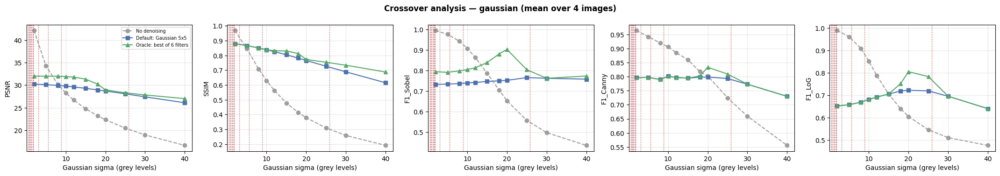

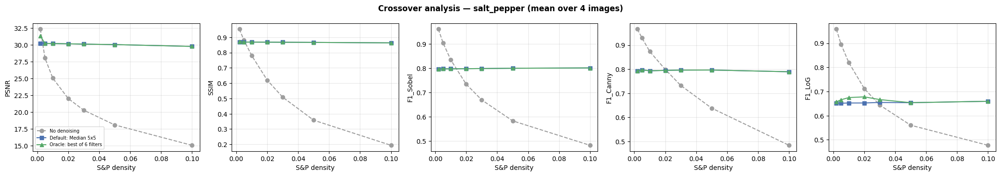


Noise-estimator check (true sigma -> mean estimated sigma on the noisy image):
Level
2      3.20
5      5.76
8      8.49
10    10.32
12    12.21
15    15.05
18    17.83
20    19.67
25    24.23
30    28.66
40    37.25

Crossover — gaussian: noise level above which denoising beats no-denoising (nan = never)
  Metric DefaultFilter  Cross_default  SigmaEst_default Note_default  Cross_oracle  SigmaEst_oracle  Note_oracle
    PSNR  Gaussian 5x5          8.283             8.745 interpolated         6.673            7.279 interpolated
    SSIM  Gaussian 5x5          4.426             5.270 interpolated         4.426            5.270 interpolated
F1_Sobel  Gaussian 5x5         16.408            16.357 interpolated        13.471           13.602 interpolated
F1_Canny  Gaussian 5x5         20.257            19.904 interpolated        18.662           18.441 interpolated
  F1_LoG  Gaussian 5x5         14.987            15.041 interpolated        14.987           15.041 interpolated

Crossover — s

In [18]:
# Fine noise-level sweep + crossover points
METRICS = ['PSNR', 'SSIM', 'F1_Sobel', 'F1_Canny', 'F1_LoG']

def run_sweep(make_fn, levels, seed_offset):
    rows = []
    for iname, orig in IMAGES.items():
        for li, L in enumerate(levels):
            rng = np.random.default_rng([SEED, seed_offset + IMG_INDEX[iname], li])
            noisy = make_fn(orig, L, rng)
            _, q, e, _ = evaluate_variants(orig, noisy, DET_PARAMS[iname], ORIG_EDGES[iname])
            f1 = {(r['Filter'], r['Detector']): r['F1'] for r in e}
            s_est = estimate_noise_sigma(noisy)
            for r in q:
                row = dict(Image=iname, Level=L, Filter=r['Filter'], PSNR=r['PSNR'], SSIM=r['SSIM'], SigmaEstRaw=s_est)
                row.update({f'F1_{d}': f1[(r['Filter'], d)] for d in DETECTORS})
                rows.append(row)
    return pd.DataFrame(rows)

def crossover(levels, gain):
    """First level from which `gain` stays > 0 for every higher noise level (linear interpolation of the zero crossing)."""
    levels, gain = np.asarray(levels, float), np.asarray(gain, float)
    for i in range(len(gain)):
        if gain[i] > 0 and (gain[i:] > 0).all():
            if i == 0:
                return float(levels[0]), 'helps at every tested level'
            x0, x1, g0, g1 = levels[i - 1], levels[i], gain[i - 1], gain[i]
            return float(x0 + (0 - g0) * (x1 - x0) / (g1 - g0)), 'interpolated'
    return float('nan'), 'never helps'

def crossover_table(df, default_filter):
    levels = list(dict.fromkeys(df.Level))            # keep the order = increasing noise severity
    m = df.groupby(['Level', 'Filter'])[METRICS].mean()
    sig = df[df.Filter == BASELINE].groupby('Level').SigmaEstRaw.mean().reindex(levels).values
    rows = []
    for met in METRICS:
        raw = np.array([m.loc[(L, BASELINE), met] for L in levels])
        dfl = np.array([m.loc[(L, default_filter), met] for L in levels])
        orc = np.array([max(m.loc[(L, f), met] for f in FILTERS) for L in levels])
        xd, sd = crossover(levels, dfl - raw)
        xo, so = crossover(levels, orc - raw)
        order = np.argsort(levels)                      # np.interp needs increasing x (photon levels are descending)
        sig_of = lambda x: float(np.interp(x, np.asarray(levels, float)[order], np.asarray(sig, float)[order])) if not np.isnan(x) else float('nan')
        rows.append(dict(Metric=met, DefaultFilter=default_filter, Cross_default=xd, SigmaEst_default=sig_of(xd), Note_default=sd,
                         Cross_oracle=xo, SigmaEst_oracle=sig_of(xo), Note_oracle=so))
    return pd.DataFrame(rows)

def plot_crossover(df, default_filter, xlabel, title, fname, vlines=None, log_inverted=False):
    levels = list(dict.fromkeys(df.Level))
    m = df.groupby(['Level', 'Filter'])[METRICS].mean()
    fig, axes = plt.subplots(1, len(METRICS), figsize=(4.3 * len(METRICS), 3.8))
    for ax, met in zip(axes, METRICS):
        raw = [m.loc[(L, BASELINE), met] for L in levels]
        dfl = [m.loc[(L, default_filter), met] for L in levels]
        orc = [max(m.loc[(L, f), met] for f in FILTERS) for L in levels]
        ax.plot(levels, raw, 'o--', color='#9e9e9e', label='No denoising')
        ax.plot(levels, dfl, 's-', color='#4C72B0', label=f'Default: {default_filter}')
        ax.plot(levels, orc, '^-', color='#55A868', label='Oracle: best of 6 filters')
        if vlines:
            for nm, x in vlines.items():
                ax.axvline(x, color='#C44E52', ls=':', lw=1)
        if log_inverted:
            ax.set_xscale('log'); ax.invert_xaxis()
        ax.set_xlabel(xlabel); ax.set_ylabel(met); ax.grid(alpha=0.3)
    axes[0].legend(fontsize=7)
    fig.suptitle(title, fontweight='bold')
    plt.tight_layout(); save_fig(fig, fname); plt.show()

# --- how reliable is the noise estimator? (it is used to place real photos on the sigma axis)
floor = {n: estimate_noise_sigma(im) for n, im in IMAGES.items()}
print('Immerkaer sigma estimate on the CLEAN reference images (estimator floor caused by texture):')
print({k: round(v, 2) for k, v in floor.items()})

FINE = {
    'gaussian':    dict(levels=[2, 5, 8, 10, 12, 15, 18, 20, 25, 30, 40], make=add_gaussian,    default='Gaussian 5x5', xlabel='Gaussian sigma (grey levels)'),
    'salt_pepper': dict(levels=[0.002, 0.005, 0.01, 0.02, 0.03, 0.05, 0.10], make=add_salt_pepper, default='Median 5x5',   xlabel='S&P density'),
}
FINE_DF, CROSS = {}, {}
real_sig = {k: float(v.loc['Raw noisy', 'NoiseSigmaEst']) for k, v in REAL_RESULTS.items() if not k.startswith('DEMO')}
for off, (nkey, cfg) in zip([2000, 3000], FINE.items()):
    FINE_DF[nkey] = run_sweep(cfg['make'], cfg['levels'], off)
    FINE_DF[nkey].to_csv(os.path.join(OUT_DIR, f'results_fine_sweep_{nkey}.csv'), index=False)
    CROSS[nkey] = crossover_table(FINE_DF[nkey], cfg['default'])
    plot_crossover(FINE_DF[nkey], cfg['default'], cfg['xlabel'], f'Crossover analysis — {nkey} (mean over {len(IMAGES)} images)',
                   f'14_crossover_{nkey}.png', vlines=real_sig if nkey == 'gaussian' else None)

est_cal = FINE_DF['gaussian'][FINE_DF['gaussian'].Filter == BASELINE].groupby('Level').SigmaEstRaw.mean()
print('\nNoise-estimator check (true sigma -> mean estimated sigma on the noisy image):')
print(est_cal.round(2).to_string())
for nkey in FINE:
    print(f'\nCrossover — {nkey}: noise level above which denoising beats no-denoising (nan = never)')
    print(CROSS[nkey].round(3).to_string(index=False))
if real_sig:
    print('\nEstimated sigma of your real photos (dotted red lines in the Gaussian plot):', {k: round(v, 2) for k, v in real_sig.items()})

## 14. Space / low-light sensor noise (photon-limited imaging)
Telescope, astronomy and low-light cameras collect very few photons, so the dominant noise is **Poisson shot noise** —
*signal dependent* (bright areas are noisier in absolute terms) — plus Gaussian read noise and a few **hot pixels / cosmic-ray hits** (impulses). This is the realistic version of the "high-noise image" case that plain Gaussian noise only approximates.

---
`peak` = expected photon count for a white pixel. **Lower peak = fewer photons = noisier image.**
Read noise sigma = 3 grey levels and 0.1% hot pixels are added at every level.

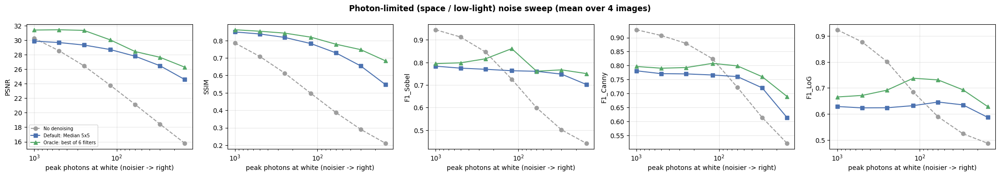

Raw noisy image: estimated sigma at each photon level (so you can place real photos on this scale):
Level
1000     7.11
500      8.87
250     11.52
120     15.76
60      21.37
30      29.27
15      39.68

Mean PSNR by filter and photon level:
Filter  None (noisy)  Mean 5x5  Median 5x5  Gaussian 5x5  Bilateral  NL-Means  Median3+Bilateral
Level                                                                                           
1000           30.27     28.55       29.88         29.96      29.03     31.41              29.18
500            28.55     28.46       29.68         29.82      29.00     31.45              29.11
250            26.48     28.34       29.34         29.61      28.97     31.36              28.99
120            23.79     28.04       28.72         29.15      28.81     30.05              28.75
60             21.14     27.56       27.80         28.44      28.32     24.35              28.34
30             18.43     26.77       26.49         27.34      26.90     18.93 

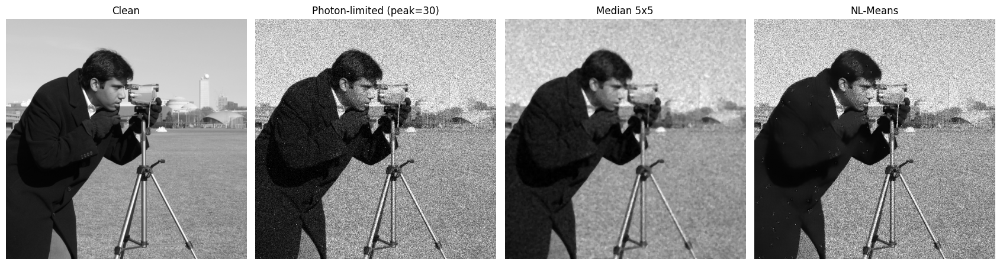

In [19]:
# Photon-limited (space / low-light) noise sweep
def add_photon_limited(img, peak, rng, read_sigma=3.0, hot_frac=0.001):
    lam = img.astype(np.float64) / 255.0 * peak                 # expected photons per pixel
    out = rng.poisson(lam).astype(np.float64) / peak * 255.0    # Poisson shot noise, back to grey levels
    out += rng.normal(0.0, read_sigma, img.shape)               # electronic read noise
    out[rng.random(img.shape) < hot_frac] = 255                 # hot pixels / cosmic-ray hits
    return np.clip(np.rint(out), 0, 255).astype(np.uint8)

PEAKS = [1000, 500, 250, 120, 60, 30, 15]                       # decreasing photons = increasing noise
LOWLIGHT_DF = run_sweep(add_photon_limited, PEAKS, 4000)
LOWLIGHT_DF.to_csv(os.path.join(OUT_DIR, 'results_lowlight_sweep.csv'), index=False)
CROSS_LL = crossover_table(LOWLIGHT_DF, 'Median 5x5')
plot_crossover(LOWLIGHT_DF, 'Median 5x5', 'peak photons at white (noisier -> right)',
               f'Photon-limited (space / low-light) noise sweep (mean over {len(IMAGES)} images)',
               '15_lowlight_sweep.png', log_inverted=True)

print('Raw noisy image: estimated sigma at each photon level (so you can place real photos on this scale):')
print(LOWLIGHT_DF[LOWLIGHT_DF.Filter == BASELINE].groupby('Level', sort=False).SigmaEstRaw.mean().round(2).to_string())
print('\nMean PSNR by filter and photon level:')
print(LOWLIGHT_DF.pivot_table(index='Level', columns='Filter', values='PSNR', aggfunc='mean', sort=False)[ALL_VARIANTS].round(2).to_string())
print('\nMean Canny edge F1 by filter and photon level:')
print(LOWLIGHT_DF.pivot_table(index='Level', columns='Filter', values='F1_Canny', aggfunc='mean', sort=False)[ALL_VARIANTS].round(3).to_string())
print('\nCrossover (in peak photons; denoising helps for peak at or below this value; nan = never):')
print(CROSS_LL.round(3).to_string(index=False))

fig, axes = plt.subplots(1, 4, figsize=(17, 4.4))
nk = PEAKS[-2]
rng = np.random.default_rng([SEED, 5000])
ll = add_photon_limited(IMAGES[first], nk, rng)
p_ = DET_PARAMS[first]
vers = [('Clean', IMAGES[first]), (f'Photon-limited (peak={nk})', ll), ('Median 5x5', FILTERS['Median 5x5'](ll)), ('NL-Means', FILTERS['NL-Means'](ll))]
for ax, (t, im) in zip(axes, vers):
    ax.imshow(im, cmap='gray', vmin=0, vmax=255); ax.set_title(t); ax.axis('off')
plt.tight_layout(); save_fig(fig, '16_lowlight_example.png'); plt.show()

## 15. Robustness check — does the conclusion depend on the frozen thresholds?
In the main experiment every version is judged with thresholds calibrated on the **clean** image. Smoothing weakens gradients, so that rule could unfairly penalise denoised images. As a check, **every version (raw or denoised) gets its own thresholds**, set by the same rule (top 10% gradients etc.) from that version itself. This is the best case for each version and for plain "do nothing". If denoising still loses at low noise, the "denoising costs edge quality" finding is not an artefact.

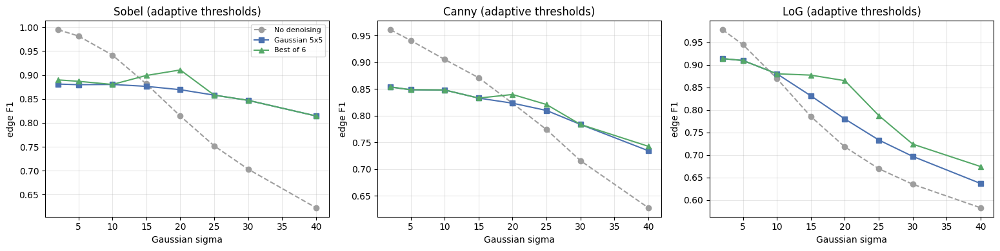

Crossover sigma with ADAPTIVE thresholds (compare with the frozen-threshold table above):
Detector  Cross_default Note_default  Cross_oracle  Note_oracle  Gain_default_sigma2  Gain_default_sigma40
   Sobel         15.420 interpolated        13.881 interpolated               -0.114                 0.192
   Canny         19.981 interpolated        18.494 interpolated               -0.107                 0.107
     LoG          8.838 interpolated         8.838 interpolated               -0.064                 0.054

Sobel: mean edge F1 by sigma (adaptive thresholds)
Filter  None (noisy)  Mean 5x5  Median 5x5  Gaussian 5x5  Bilateral  NL-Means  Median3+Bilateral
Level                                                                                           
2              0.995     0.829       0.890         0.881      0.808     0.866              0.814
5              0.981     0.829       0.887         0.880      0.809     0.869              0.812
10             0.942     0.829       0.880

In [20]:
# Robustness: adaptive (per-version) thresholds, Gaussian noise
ROB_LEVELS = [2, 5, 10, 15, 20, 25, 30, 40]
rob_rows = []
for iname, orig in IMAGES.items():
    gt = ORIG_EDGES[iname]
    for li, L in enumerate(ROB_LEVELS):
        rng = np.random.default_rng([SEED, 7000 + IMG_INDEX[iname], li])
        noisy = add_gaussian(orig, L, rng)
        variants = {BASELINE: noisy, **{k: f(noisy) for k, f in FILTERS.items()}}
        for v, im in variants.items():
            p_ = calibrate_detectors(im)                         # thresholds from the version itself
            for d in DETECTORS:
                rob_rows.append(dict(Image=iname, Level=L, Filter=v, Detector=d,
                                     F1=edge_scores(detect(d, im, p_), gt[d])['F1']))
ROB_DF = pd.DataFrame(rob_rows)
ROB_DF.to_csv(os.path.join(OUT_DIR, 'results_robustness_adaptive_thresholds.csv'), index=False)

ROB_CROSS = []
fig, axes = plt.subplots(1, len(DETECTORS), figsize=(5.2 * len(DETECTORS), 4))
for ax, d in zip(axes, DETECTORS):
    t = ROB_DF[ROB_DF.Detector == d].pivot_table(index='Level', columns='Filter', values='F1').reindex(ROB_LEVELS)
    raw, dfl = t[BASELINE].values, t['Gaussian 5x5'].values
    orc = t[list(FILTERS)].max(axis=1).values
    xd, nd = crossover(ROB_LEVELS, dfl - raw)
    xo, no = crossover(ROB_LEVELS, orc - raw)
    ROB_CROSS.append(dict(Detector=d, Cross_default=xd, Note_default=nd, Cross_oracle=xo, Note_oracle=no,
                          Gain_default_sigma2=dfl[0] - raw[0], Gain_default_sigma40=dfl[-1] - raw[-1]))
    ax.plot(ROB_LEVELS, raw, 'o--', color='#9e9e9e', label='No denoising')
    ax.plot(ROB_LEVELS, dfl, 's-', color='#4C72B0', label='Gaussian 5x5')
    ax.plot(ROB_LEVELS, orc, '^-', color='#55A868', label='Best of 6')
    ax.set_title(f'{d} (adaptive thresholds)'); ax.set_xlabel('Gaussian sigma'); ax.set_ylabel('edge F1'); ax.grid(alpha=0.3)
axes[0].legend(fontsize=8)
plt.tight_layout(); save_fig(fig, '17_robustness_adaptive_thresholds.png'); plt.show()
ROB_CROSS = pd.DataFrame(ROB_CROSS)
print('Crossover sigma with ADAPTIVE thresholds (compare with the frozen-threshold table above):')
print(ROB_CROSS.round(3).to_string(index=False))
for d in DETECTORS:
    print(f'\n{d}: mean edge F1 by sigma (adaptive thresholds)')
    print(ROB_DF[ROB_DF.Detector == d].pivot_table(index='Level', columns='Filter', values='F1')[ALL_VARIANTS].round(3).to_string())